## Big Data and Data Mining


### UK 2020 Road Traffic Accident Analysis

All road traffic accidents involving casualties are logged and reported in Great Britain, along
with (probably) a majority of other non-fatal road traffic accidents. Every year, the government
releases a large batch of data associated with these reports. In this project, we will be using the data from 2020. I will extensively analyse the data and generate insights to provide recommendations for government agencies to improve road traffic safety

In [1]:
# Import libraries for reading the data and plotting visualizations
import sqlite3
import pandas as pd
import numpy as np
import seaborn as sns
from numpy import mean, std
from matplotlib import pyplot
import random
import matplotlib.pyplot as plt
%matplotlib inline

# Libraries for clustering and classification tasks
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import StackingClassifier
from imblearn.under_sampling import RandomUnderSampler
from scipy import stats


#libraries for apriori algorithm
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

#### Connect to the database

In [2]:
#connect to the database and assign the connection to a variable con
con = sqlite3.connect("accident_data_v1.0.0_2023.db") 
cur = con.cursor()

There are four tables in the database. We will read in this tables and convert them to pandas dataframes

In [4]:
#query the accident table columns
accident_col_info = cur.execute(f"PRAGMA table_info(accident)") 
accident_col = accident_col_info.fetchall()

In [5]:
vehicle_col_info = cur.execute(f"PRAGMA table_info(vehicle)")   #read in table vehicle
vehicle_col = vehicle_col_info.fetchall()

In [6]:
casualty_col_info = cur.execute(f"PRAGMA table_info(casualty)")  #read in table casualty
casualty_col = casualty_col_info.fetchall()

In [7]:
lsoa_col_info = cur.execute(f"PRAGMA table_info(lsoa)")  #read in table lsoa
lsoa_col = lsoa_col_info.fetchall()

In [8]:
# To print the column names in the table
#assign the column names to a list using list comprehesion
a_col_list = [i[1] for i in accident_col]  
print(a_col_list)

['accident_index', 'accident_year', 'accident_reference', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'accident_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control', 'pedestrian_crossing_physical_facilities', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location']


In [9]:
# To print the column names in the table
#assign the column names to a list using list comprehesion
v_col_list = [i[1] for i in vehicle_col]   
print(v_col_list)

['vehicle_index', 'accident_index', 'accident_year', 'accident_reference', 'vehicle_reference', 'vehicle_type', 'towing_and_articulation', 'vehicle_manoeuvre', 'vehicle_direction_from', 'vehicle_direction_to', 'vehicle_location_restricted_lane', 'junction_location', 'skidding_and_overturning', 'hit_object_in_carriageway', 'vehicle_leaving_carriageway', 'hit_object_off_carriageway', 'first_point_of_impact', 'vehicle_left_hand_drive', 'journey_purpose_of_driver', 'sex_of_driver', 'age_of_driver', 'age_band_of_driver', 'engine_capacity_cc', 'propulsion_code', 'age_of_vehicle', 'generic_make_model', 'driver_imd_decile', 'driver_home_area_type']


In [10]:
# To print the column names in the table
#assign the column names to a list using list comprehesion
c_col_list = [i[1] for i in casualty_col]    
print(c_col_list)

['casualty_index', 'accident_index', 'accident_year', 'accident_reference', 'vehicle_reference', 'casualty_reference', 'casualty_class', 'sex_of_casualty', 'age_of_casualty', 'age_band_of_casualty', 'casualty_severity', 'pedestrian_location', 'pedestrian_movement', 'car_passenger', 'bus_or_coach_passenger', 'pedestrian_road_maintenance_worker', 'casualty_type', 'casualty_home_area_type', 'casualty_imd_decile']


In [11]:
l_col_list = [i[1] for i in lsoa_col]  # Assign the columns names to a list
print(l_col_list) # prints the columns in lsoa table

['objectid', 'lsoa01cd', 'lsoa01nm', 'lsoa01nmw', 'shape__area', 'shape__length', 'globalid']


#### Filtering out the 2020 Data 

The project is focused on the 2020 accident data. I will filter this out from the database uding the where statement

In [12]:
a_2020 = cur.execute('''SELECT * from accident WHERE accident_year = 2020''')    #Filtering out the 2020 data for table accident
a_2020 = a_2020.fetchall()


In [13]:
v_2020 = cur.execute("SELECT * from vehicle WHERE accident_year = 2020")    #Filtering out the 2020 data for table accident
v_2020 = v_2020.fetchall()

In [14]:
c_2020 = cur.execute("SELECT * from casualty WHERE accident_year = 2020")     #Filtering out the 2020 data for table accident
c_2020 = c_2020.fetchall()

In [15]:
lso = cur.execute("SELECT * from lsoa")     #lsoa table data
lsoa = lso.fetchall()

#### Reading the Data into PAndas DataFrame

In [16]:
a_data = pd.DataFrame(a_2020, columns=a_col_list)    # reading the accident data into pandas and
a_data.head()                                        # naming the columns with the list printed earlier

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
0,2020010219808,2020,010219808,521389.0,175144.0,-0.254001,51.462262,1,3,1,...,9,1,9,9,0,0,1,3,2,E01004576
1,2020010220496,2020,010220496,529337.0,176237.0,-0.139253,51.470327,1,3,1,...,4,1,1,1,0,0,1,1,2,E01003034
2,2020010228005,2020,010228005,526432.0,182761.0,-0.178719,51.529614,1,3,1,...,0,4,1,2,0,0,1,1,2,E01004726
3,2020010228006,2020,010228006,538676.0,184371.0,-0.001683,51.541210,1,2,1,...,4,4,1,1,0,0,1,1,2,E01003617
4,2020010228011,2020,010228011,529324.0,181286.0,-0.137592,51.515704,1,3,1,...,0,4,1,1,0,0,1,1,2,E01004763


In [17]:
v_data = pd.DataFrame(v_2020, columns=v_col_list)     # reading the vehicle data into pandas and
v_data.head()                                         # naming the columns with the list printed earlier

,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,...,journey_purpose_of_driver,sex_of_driver,age_of_driver,age_band_of_driver,engine_capacity_cc,propulsion_code,age_of_vehicle,generic_make_model,driver_imd_decile,driver_home_area_type
0,681716,2020010219808,2020,010219808,1,9,9,5,1,5,...,6,2,32,6,1968,2,6,AUDI Q5,4,1
1,681717,2020010220496,2020,010220496,1,9,0,4,2,6,...,2,1,45,7,1395,1,2,AUDI A1,7,1
2,681718,2020010228005,2020,010228005,1,9,0,18,-1,-1,...,6,3,-1,-1,-1,-1,-1,-1,-1,-1
3,681719,2020010228006,2020,010228006,1,8,0,18,1,5,...,1,1,44,7,1798,8,8,TOYOTA PRIUS,2,1
4,681720,2020010228011,2020,010228011,1,9,0,18,3,7,...,6,1,20,4,2993,2,4,BMW 4 SERIES,-1,-1


In [18]:
c_data = pd.DataFrame(c_2020, columns=c_col_list)       # reading the vehicle data into pandas and
c_data.head()                                           # naming the columns with the list printed earlier

,casualty_index,accident_index,accident_year,accident_reference,vehicle_reference,casualty_reference,casualty_class,sex_of_casualty,age_of_casualty,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_home_area_type,casualty_imd_decile
0,484748,2020010219808,2020,010219808,1,1,3,1,31,6,3,9,5,0,0,0,0,1,4
1,484749,2020010220496,2020,010220496,1,1,3,2,2,1,3,1,1,0,0,0,0,1,2
2,484750,2020010220496,2020,010220496,1,2,3,2,4,1,3,1,1,0,0,0,0,1,2
3,484751,2020010228005,2020,010228005,1,1,3,1,23,5,3,5,9,0,0,0,0,1,3
4,484752,2020010228006,2020,010228006,1,1,3,1,47,8,2,4,1,0,0,0,0,1,3


In [19]:
l_data = pd.DataFrame(lsoa, columns=l_col_list)    # reading the accident data into pandas and
l_data.head()                                        # naming the columns with the list printed earlier


,objectid,lsoa01cd,lsoa01nm,lsoa01nmw,shape__area,shape__length,globalid
0,1,E01000001,City of London 001A,City of London 001A,1.298652e+05,2635.772001,68cc6127-1008-4fbe-a16c-78fb089a7c43
1,2,E01000002,City of London 001B,City of London 001B,2.284189e+05,2707.986202,937edbc3-c1bf-4d35-b274-b0a1480a7c09
2,3,E01000003,City of London 001C,City of London 001C,5.905477e+04,1224.774479,2686dcaf-10b9-4736-92af-4788d4feaa69
3,4,E01000004,City of London 001D,City of London 001D,2.544551e+06,10718.466240,3c493140-0b3f-4b9a-b358-22011dc5fb89
4,5,E01000005,City of London 001E,City of London 001E,1.895782e+05,2275.809358,b569093d-788d-41be-816c-d6d7658b2311


#### Data Cleaning

Checking for null entries in all the tables

In [20]:
a_data.isnull().sum() # Null entries in the accident table

accident_index                                  0
accident_year                                   0
accident_reference                              0
location_easting_osgr                          14
location_northing_osgr                         14
longitude                                      14
latitude                                       14
police_force                                    0
accident_severity                               0
number_of_vehicles                              0
number_of_casualties                            0
date                                            0
day_of_week                                     0
time                                            0
local_authority_district                        0
local_authority_ons_district                    0
local_authority_highway                         0
first_road_class                                0
first_road_number                               0
road_type                                       0


In [22]:
v_data.isnull().sum() # Null entries in the vehicle table

vehicle_index                       0
accident_index                      0
accident_year                       0
accident_reference                  0
vehicle_reference                   0
vehicle_type                        0
towing_and_articulation             0
vehicle_manoeuvre                   0
vehicle_direction_from              0
vehicle_direction_to                0
vehicle_location_restricted_lane    0
junction_location                   0
skidding_and_overturning            0
hit_object_in_carriageway           0
vehicle_leaving_carriageway         0
hit_object_off_carriageway          0
first_point_of_impact               0
vehicle_left_hand_drive             0
journey_purpose_of_driver           0
sex_of_driver                       0
age_of_driver                       0
age_band_of_driver                  0
engine_capacity_cc                  0
propulsion_code                     0
age_of_vehicle                      0
generic_make_model                  0
driver_imd_d

In [23]:
c_data.isnull().sum()  # Null entries in the casualty table

casualty_index                        0
accident_index                        0
accident_year                         0
accident_reference                    0
vehicle_reference                     0
casualty_reference                    0
casualty_class                        0
sex_of_casualty                       0
age_of_casualty                       0
age_band_of_casualty                  0
casualty_severity                     0
pedestrian_location                   0
pedestrian_movement                   0
car_passenger                         0
bus_or_coach_passenger                0
pedestrian_road_maintenance_worker    0
casualty_type                         0
casualty_home_area_type               0
casualty_imd_decile                   0
dtype: int64

#### Correcting the null entries. 

Only the accident data has null entries. The null entries are in 4 columns but the same row. I must clean it before I proceed
To do this, I will have to view the records with the null entries. This can help inform the decision I will make

In [24]:
a_data[a_data['location_easting_osgr'].isna()]

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
25520,2020052002442,2020,052002442,NaN,NaN,NaN,NaN,5,2,2,...,0,1,1,1,0,0,3,1,2,-1
29452,2020070769852,2020,070769852,NaN,NaN,NaN,NaN,7,3,2,...,0,1,1,1,0,0,3,1,2,-1
32689,2020122001194,2020,122001194,NaN,NaN,NaN,NaN,12,3,2,...,0,1,2,2,0,0,3,1,2,-1
33578,2020137330369,2020,137330369,NaN,NaN,NaN,NaN,13,3,2,...,0,1,1,1,0,0,3,1,1,-1
81252,2020522005114,2020,522005114,NaN,NaN,NaN,NaN,52,3,3,...,0,7,1,1,0,0,3,1,2,-1
86437,2020622001016,2020,622001016,NaN,NaN,NaN,NaN,62,3,2,...,5,4,1,1,0,0,3,1,-1,-1
86642,202063A017520,2020,63A017520,NaN,NaN,NaN,NaN,63,3,2,...,0,1,9,-1,0,0,3,2,-1,-1
86651,202063A018920,2020,63A018920,NaN,NaN,NaN,NaN,63,3,2,...,0,1,9,1,0,0,3,2,-1,-1
86668,202063A025020,2020,63A025020,NaN,NaN,NaN,NaN,63,3,2,...,0,1,2,2,0,0,3,2,-1,-1
86705,202063A035620,2020,63A035620,NaN,NaN,NaN,NaN,63,3,1,...,0,1,1,1,0,0,3,2,-1,-1


As seen from the output above, accident reference is generated with the police force number starting the series. This means that the accidents happening in the same police force region starts with the same 2 digits.

In [25]:
a_data[a_data['police_force'] == 63]

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
86592,2020632000892,2020,632000892,284537.0,211380.0,-3.675463,51.789128,63,3,2,...,0,1,1,1,0,0,2,1,-1,W01000496
86593,2020632001002,2020,632001002,290308.0,207467.0,-3.590589,51.755121,63,3,1,...,0,1,1,2,0,0,2,1,-1,W01000496
86594,202063A000320,2020,63A000320,262830.0,221570.0,-3.994042,51.875788,63,3,1,...,0,4,1,1,0,0,2,1,-1,W01000677
86595,202063A001220,2020,63A001220,252080.0,243420.0,-4.159508,52.069351,63,2,1,...,0,1,1,1,0,0,2,1,-1,W01000702
86596,202063A001321,2020,63A001321,251510.0,202390.0,-4.150151,51.700560,63,3,2,...,0,1,1,1,0,0,2,1,-1,W01000655
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87358,202063D087420,2020,63D087420,324240.0,306420.0,-3.121276,52.650214,63,2,1,...,0,1,1,2,0,0,2,1,-1,W01000441
87359,202063DF01120,2020,63DF01120,325360.0,319840.0,-3.107776,52.770987,63,1,1,...,0,1,1,1,0,0,2,1,-1,W01000458
87360,202063DF01220,2020,63DF01220,322000.0,243260.0,-3.139679,52.082186,63,1,6,...,0,1,1,1,0,0,2,1,-1,W01000443
87361,202063DF01520,2020,63DF01520,297230.0,220710.0,-3.494276,51.875464,63,1,1,...,0,6,1,1,0,0,2,1,-1,W01001897


In [26]:
a_data[a_data['accident_reference'].str.contains('63A01', case = False)]

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
86619,202063A010120,2020,63A010120,235020.0,212890.0,-4.393543,51.790279,63,3,2,...,0,1,1,2,0,0,2,1,-1,W01000700
86620,202063A010320,2020,63A010320,252520.0,199960.0,-4.134519,51.678993,63,3,2,...,0,4,9,1,0,0,2,2,-1,W01000628
86621,202063A011220,2020,63A011220,238750.0,219310.0,-4.342500,51.849041,63,2,1,...,0,1,1,2,0,0,2,1,-1,W01000642
86622,202063A011420,2020,63A011420,249670.0,217070.0,-4.183112,51.831965,63,3,1,...,0,4,5,2,0,0,2,1,-1,W01000675
86623,202063A011920,2020,63A011920,242430.0,222420.0,-4.290537,51.878031,63,2,1,...,0,6,2,2,0,0,2,1,-1,W01000640
86624,202063A012020,2020,63A012020,264260.0,212400.0,-3.969682,51.793739,63,3,1,...,0,1,5,2,0,0,1,1,-1,W01000715
86625,202063A012220,2020,63A012220,268310.0,214440.0,-3.911767,51.813040,63,3,2,...,0,1,5,2,0,0,2,1,-1,W01000656
86626,202063A012320,2020,63A012320,248700.0,202210.0,-4.190704,51.698192,63,3,2,...,0,1,2,2,0,0,2,1,-1,W01001925
86627,202063A012620,2020,63A012620,251110.0,201480.0,-4.155547,51.692277,63,3,2,...,0,1,1,1,0,0,1,1,-1,W01000704
86628,202063A012820,2020,63A012820,239520.0,211830.0,-4.327864,51.782065,63,3,2,...,0,1,1,1,0,0,2,2,-1,W01000722


Looking at the output above, accidents in the same police force regions are arranged together. Hence I  will use the interpolation method to fill the Null entries

In [27]:
a_data['location_easting_osgr'].interpolate(method = 'linear', inplace = True)
a_data['location_northing_osgr'].interpolate(method = 'linear', inplace = True)
a_data['longitude'].interpolate(method = 'linear', inplace = True)
a_data['latitude'].interpolate(method = 'linear', inplace = True)

In [28]:
#to reconfirm that the null data is gone
a_data[a_data['accident_reference'].str.contains('63A01', case = False)]

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
86619,202063A010120,2020,63A010120,235020.0,212890.0,-4.393543,51.790279,63,3,2,...,0,1,1,2,0,0,2,1,-1,W01000700
86620,202063A010320,2020,63A010320,252520.0,199960.0,-4.134519,51.678993,63,3,2,...,0,4,9,1,0,0,2,2,-1,W01000628
86621,202063A011220,2020,63A011220,238750.0,219310.0,-4.342500,51.849041,63,2,1,...,0,1,1,2,0,0,2,1,-1,W01000642
86622,202063A011420,2020,63A011420,249670.0,217070.0,-4.183112,51.831965,63,3,1,...,0,4,5,2,0,0,2,1,-1,W01000675
86623,202063A011920,2020,63A011920,242430.0,222420.0,-4.290537,51.878031,63,2,1,...,0,6,2,2,0,0,2,1,-1,W01000640
86624,202063A012020,2020,63A012020,264260.0,212400.0,-3.969682,51.793739,63,3,1,...,0,1,5,2,0,0,1,1,-1,W01000715
86625,202063A012220,2020,63A012220,268310.0,214440.0,-3.911767,51.813040,63,3,2,...,0,1,5,2,0,0,2,1,-1,W01000656
86626,202063A012320,2020,63A012320,248700.0,202210.0,-4.190704,51.698192,63,3,2,...,0,1,2,2,0,0,2,1,-1,W01001925
86627,202063A012620,2020,63A012620,251110.0,201480.0,-4.155547,51.692277,63,3,2,...,0,1,1,1,0,0,1,1,-1,W01000704
86628,202063A012820,2020,63A012820,239520.0,211830.0,-4.327864,51.782065,63,3,2,...,0,1,1,1,0,0,2,2,-1,W01000722


# Checking for Bad Data

### Accident Table

In [29]:
a_data.describe() # to get the info on all columns

,accident_year,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,number_of_casualties,day_of_week,...,pedestrian_crossing_human_control,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag
count,91199.0,91199.000000,9.119900e+04,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,...,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000,91199.000000
mean,2020.0,456463.848661,2.737639e+05,-1.189605,52.351068,27.488043,2.768232,1.835272,1.267382,4.121558,...,0.352975,1.185309,2.065308,1.702047,1.391583,0.244740,0.180594,1.323205,1.415268,1.721521
std,0.0,93530.248045,1.473451e+05,1.368036,1.327515,24.548964,0.456682,0.677272,0.681473,1.932200,...,1.698116,2.445924,1.747690,1.845786,0.925690,1.318554,1.149791,0.468031,0.665469,0.801491
min,2020.0,65947.000000,1.271500e+04,-7.497375,49.970479,1.000000,1.000000,1.000000,1.000000,1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,-1.000000,-1.000000
25%,2020.0,392878.000000,1.745720e+05,-2.108390,51.457249,4.000000,3.000000,1.000000,1.000000,2.000000,...,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,2.000000
50%,2020.0,465494.000000,2.086300e+05,-1.047384,51.763518,22.000000,3.000000,2.000000,1.000000,4.000000,...,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,2.000000
75%,2020.0,530167.000000,3.783655e+05,-0.125277,53.297298,45.000000,3.000000,2.000000,1.000000,6.000000,...,0.000000,0.000000,4.000000,1.000000,2.000000,0.000000,0.000000,2.000000,2.000000,2.000000
max,2020.0,655138.000000,1.184351e+06,1.756257,60.541144,99.000000,3.000000,13.000000,41.000000,7.000000,...,9.000000,9.000000,7.000000,9.000000,9.000000,9.000000,9.000000,3.000000,3.000000,2.000000


I can see that there are some columns with -1 as the minimum, which shouldnt be. As there are no entries of -1 in the STAT19 form. I will remove all -1 in the data and replace with NAN then critically examine the important rows that will be needed for the analysis below to determine how best to fill the nan values

In [30]:
a_data_nan = a_data.replace(-1, np.nan)

In [31]:
a_data_nan = a_data_nan.replace('-1', np.nan)

In [32]:
a_data_nan.isnull().sum()

accident_index                                     0
accident_year                                      0
accident_reference                                 0
location_easting_osgr                              0
location_northing_osgr                             0
longitude                                          0
latitude                                           0
police_force                                       0
accident_severity                                  0
number_of_vehicles                                 0
number_of_casualties                               0
date                                               0
day_of_week                                        0
time                                               0
local_authority_district                         991
local_authority_ons_district                       0
local_authority_highway                            0
first_road_class                                   0
first_road_number                             

#### Speed Limit - Bad Data

As seen above speed limit has 12 entries with -1. We will call these entries out and check to decide how best to fill them

In [33]:
a_data[a_data['speed_limit']== -1]

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
1993,2020010234355,2020,010234355,548270.0,183677.0,0.136269,51.532537,1,3,1,...,1,4,1,1,0,0,1,1,2,E01000056
5381,2020010244932,2020,010244932,527033.0,179914.0,-0.171085,51.503893,1,3,1,...,0,1,1,1,0,0,1,1,2,E01004689
16520,2020010275266,2020,010275266,548903.0,183497.0,0.145312,51.530753,1,2,1,...,1,4,2,1,0,0,1,1,2,E01000095
18039,2020010279612,2020,010279612,540131.0,169512.0,0.013394,51.407327,1,3,1,...,9,1,2,2,0,0,1,3,2,E01000676
18264,2020010280179,2020,010280179,529031.0,163756.0,-0.148194,51.358229,1,3,1,...,9,1,9,9,9,9,1,3,2,E01004178
18487,2020010280770,2020,010280770,537440.0,185948.0,-0.018879,51.555683,1,3,2,...,1,1,7,1,0,0,1,3,2,E01004429
20496,2020010286380,2020,010286380,519882.0,179251.0,-0.274291,51.499495,1,2,1,...,0,7,1,1,0,0,1,3,2,E01001358
31115,2020101009449,2020,101009449,434889.0,570038.0,-1.455831,55.023670,10,2,1,...,1,4,2,1,0,0,1,2,2,E01008557
47041,2020231004014,2020,231004014,431195.0,286045.0,-1.542189,52.471470,23,3,1,...,0,1,1,2,0,0,2,1,2,E01031027
53894,2020350934310,2020,350934310,546182.0,257330.0,0.137331,52.194846,35,3,1,...,0,1,1,1,0,0,1,2,2,E01017987


In [34]:
#Check the unique values in the column first
a_data['speed_limit'].unique()

array([20, 30, 40, 50, 60, 70, -1], dtype=int64)

[Text(0.5, 1.0, 'Speed Limit Before CLeaning')]

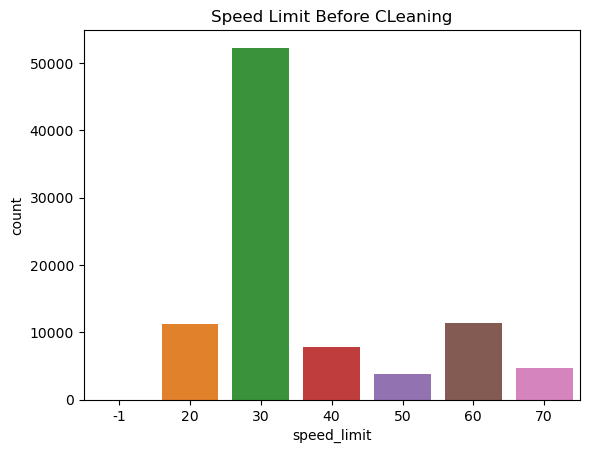

In [35]:
sns.countplot(x = 'speed_limit', data=a_data).set(title = 'Speed Limit Before CLeaning')

In [36]:
#According to the stats19 form, road type 3 are dual carriage ways and type 2 are one way streets
#type 6 are single carriage way and type 9 are unknown.
#those with type 9 are unknown also do not have 

# The speed limit used will be in accordance to the GOV.UK specified speed limit, where the road type is unknown, 
# the lowest speed limit 20 will be used.
a_data.loc[(a_data['speed_limit'] == -1 ) & (a_data['road_type'] == 3), 'speed_limit'] = 60
a_data.loc[(a_data['speed_limit'] == -1 ) & (a_data['road_type'] == 2), 'speed_limit'] = 30
a_data.loc[(a_data['speed_limit'] == -1 ) & (a_data['road_type'] == 6), 'speed_limit'] = 50
a_data.loc[(a_data['speed_limit'] == -1 ) & (a_data['road_type'] == 9), 'speed_limit'] = 20

[Text(0.5, 1.0, 'Speed Limit After Cleaning')]

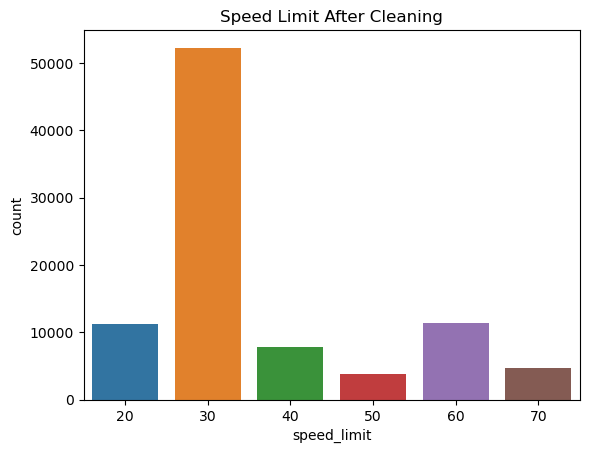

In [37]:
sns.countplot(x = 'speed_limit', data=a_data).set(title = 'Speed Limit After Cleaning')

In [240]:
# number of accidents occuring at 30mph speed limits
len(a_data[a_data['speed_limit'] == 30])/len(a_data)

0.5730545291066788

#### Junction Details, Junction Control, 2nd Road Number and 2nd Road Class - Bad Data

As seen above junction details has 2 entries with -1. We will call these entries out and check to decide how best to fill them

In [38]:
a_data[a_data['junction_detail']== -1]

,accident_index,accident_year,accident_reference,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,accident_severity,number_of_vehicles,...,pedestrian_crossing_physical_facilities,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location
65042,2020432316294,2020,432316294,482277.0,238418.0,-0.801898,52.038080,43,3,2,...,0,1,1,1,0,0,1,3,2,E01016815
80880,2020522003678,2020,522003678,375358.0,165623.0,-2.355525,51.389105,52,3,2,...,0,1,1,1,0,0,1,2,2,E01014371


In [39]:
a_data['junction_detail'].unique()

array([ 0,  9,  3,  6,  1, 99,  7,  8,  2,  5, -1], dtype=int64)

[Text(0.5, 1.0, 'Junction Details Before Cleaning')]

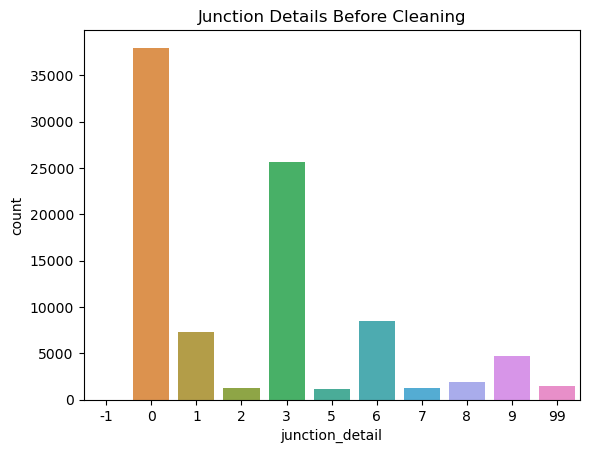

In [40]:
sns.countplot(x = 'junction_detail', data=a_data).set(title = 'Junction Details Before Cleaning')

[Text(0.5, 1.0, 'Junction Control Before Cleaning')]

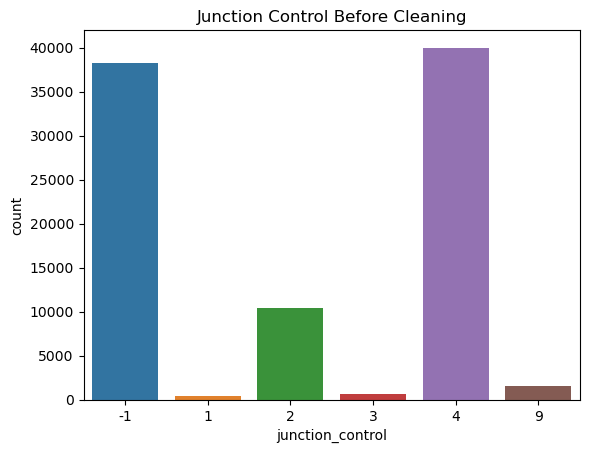

In [41]:
sns.countplot(x = 'junction_control', data=a_data).set(title = 'Junction Control Before Cleaning')

[Text(0.5, 1.0, '2nd Road Class Before Cleaning')]

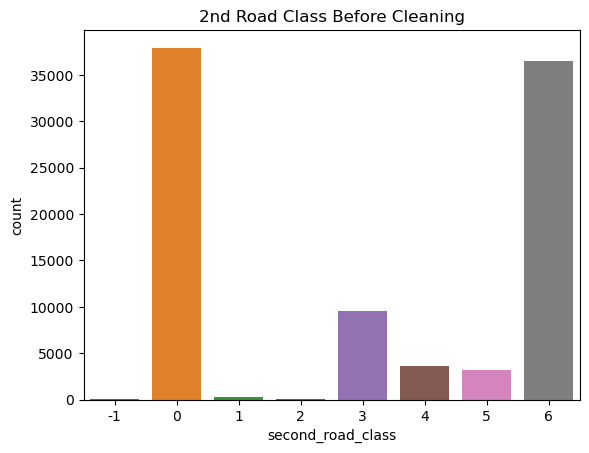

In [42]:
sns.countplot(x = 'second_road_class', data=a_data).set(title = '2nd Road Class Before Cleaning')

The junction control for one entry is 4 indicating that the accident is a junction accident. however, we do not know what type of juction it is, to be safe, we will change the entry to 09, meaning, other junction. the other can be changed to 0 since we do not have any additional junction details

In [43]:
a_data.loc[(a_data['junction_detail'] == -1 ) & (a_data['junction_control'] == -1), 'junction_detail'] = 0
a_data.loc[(a_data['junction_detail'] == -1 ) & (a_data['junction_control'] == 4), 'junction_detail'] = 9
#a_data.loc[(a_data['junction_detail'] == 99 ), 'junction_detail'] = 0

Since accident not involving junction are coded 0  in the junction details. I can use the information to correct the junction control columns. I will also enter 0 for accidents with junction detail 0

In [44]:
a_data.loc[(a_data['junction_detail'] == 0 ) & (a_data['junction_control'] == -1), 'junction_control'] = 0

In [45]:
# next, we look at entry 99
len(a_data[a_data['junction_detail']== 99])

1508

In [46]:
# looking at 99 in relatin with other junction details
ju99 = a_data[a_data['junction_detail']== 99]
ju99['second_road_class'].value_counts()

 6    1114
 3     252
 5      84
 4      56
-1       2
Name: second_road_class, dtype: int64

As seen from the above, we can infer that the '99' entries accidents actually occured at a junction and since the only similar entry in the junction detail column is 9, I will change it to reflect 9. After which we will clean the second  road class column accordingly too

In [47]:
a_data.loc[(a_data['junction_detail'] == 99 ),'junction_detail'] = 9

In [48]:
len(a_data[(a_data['junction_detail']!= 0) & (a_data['junction_control'] == 9)])


1536

We know these entries  junction details 9 are juntion accidents, we will use information about pedestrians crossing either with human control or physical facilities to fill the correct junction control record

In [49]:
a_data.loc[(a_data['junction_control'] == 9 ) & (a_data['pedestrian_crossing_human_control'] == 1) | (a_data['pedestrian_crossing_human_control'] == 2), 'junction_control'] = 1 
a_data.loc[(a_data['junction_control'] == 9 ) & (a_data['pedestrian_crossing_physical_facilities'] == 5), 'junction_control'] = 2
a_data.loc[(a_data['junction_control'] == 9 ) & (a_data['pedestrian_crossing_physical_facilities'] == 0), 'junction_control'] = 4

In [50]:
a_data['junction_control'].value_counts()

 4    40145
 0    37732
 2    10165
 1     1320
 9      947
 3      574
-1      316
Name: junction_control, dtype: int64

We are only able to clean few of the columns. Hence I will change the remaining to 0 meaning we do not have adequate information

In [51]:
a_data.loc[(a_data['junction_control'] == 9 ), 'junction_control'] = 0
a_data.loc[(a_data['junction_control'] == -1 ), 'junction_control'] = 0

In [52]:
a_data['junction_detail'].value_counts()

0    37979
3    25626
6     8429
1     7326
9     6214
8     1887
2     1300
7     1279
5     1159
Name: junction_detail, dtype: int64

[Text(0.5, 1.0, 'Junction Details After CLeaning')]

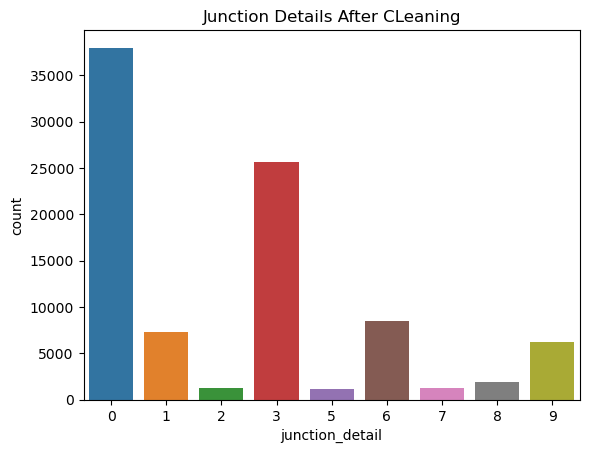

In [53]:
sns.countplot(x = 'junction_detail', data=a_data).set(title = 'Junction Details After CLeaning')

Next is the 2nd Road Details, its only peculiar to junction accidents hence we will fill by relating it to the junction details column

In [54]:
a_data.loc[(a_data['second_road_number'] == -1 ) & (a_data['junction_detail'] == 0), 'second_road_number'] = 0
a_data.loc[(a_data['second_road_class'] == -1 ) & (a_data['junction_detail'] == 0), 'second_road_class'] = 0

According to the stat19 form, where junction detail is coded as 8, then 2nd road class should be coded as 6 (unclassified).
Also, it is left to the local authority to decide if some road class C should be classified as  C otherwise classify as 6. I will classify the remaining 2nd class road as 6

In [55]:
a_data.loc[(a_data['junction_detail'] == 8 ) & (a_data['second_road_class'] == -1), 'second_road_class'] = 6
a_data.loc[(a_data['second_road_class'] == -1 ), 'second_road_class'] = 6


In [56]:
a_data.loc[(a_data['second_road_number'] == -1 ), 'second_road_number'] = 6

In [57]:
len(a_data[a_data['second_road_class']== -1])

0

2nd Road Number is dependent on if juntion con

In [58]:

a_data[a_data['second_road_number']== -1]['second_road_class'].value_counts()

Series([], Name: second_road_class, dtype: int64)

In [59]:
second_mode = a_data[(a_data['second_road_number'] != -1 ) & (a_data['second_road_number'] != 0) ]

In [60]:
a_data.loc[(a_data['second_road_number'] == -1 ) & (a_data['second_road_class'] == 3) | (a_data['second_road_class'] == 4), 'second_road_number'] =second_mode['second_road_number'].mode()[0] 
a_data.loc[(a_data['second_road_number'] == -1 ) & (a_data['second_road_class'] == 6), 'second_road_number'] = 0

[Text(0.5, 1.0, 'Junction Control After Cleaning')]

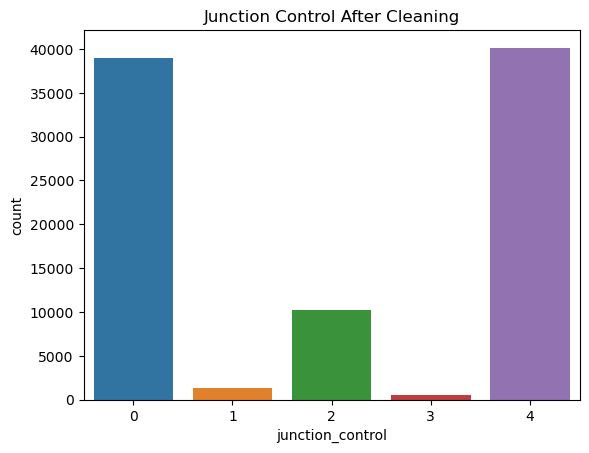

In [61]:
sns.countplot(x = 'junction_control', data=a_data).set(title = 'Junction Control After Cleaning')


[Text(0.5, 1.0, '2nd Road Class After Cleaning')]

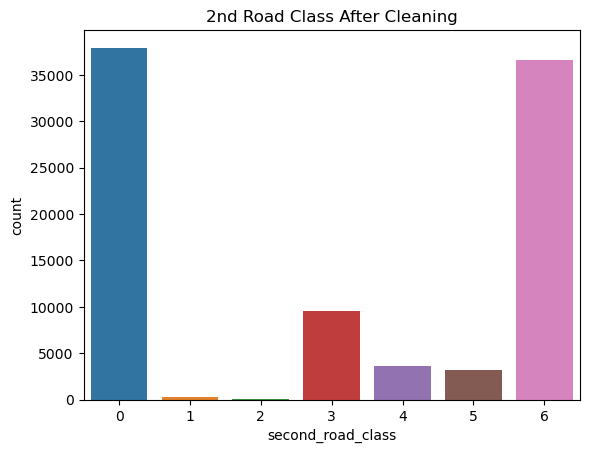

In [62]:
sns.countplot(x = 'second_road_class', data=a_data).set(title = '2nd Road Class After Cleaning')


[Text(0.5, 1.0, '2nd Road Number After Cleaning')]

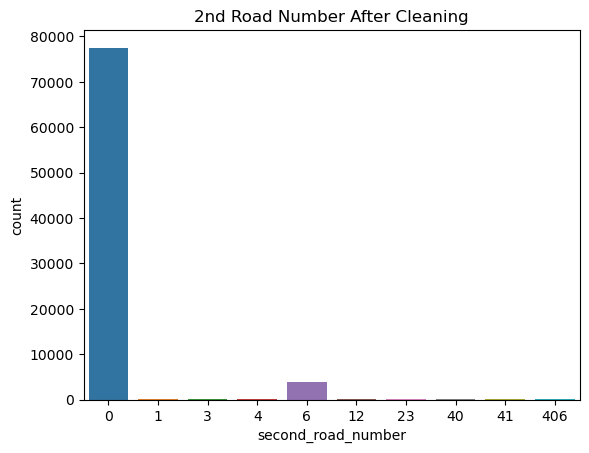

In [63]:
second_road = a_data['second_road_number'].value_counts()
top_20_road = second_road.nlargest(10).index
only_top_20 = a_data[a_data['second_road_number'].isin(top_20_road)]
sns.countplot(x = 'second_road_number', data=only_top_20).set(title = '2nd Road Number After Cleaning')

# street_counts = new_occu['Street'].value_counts()
# top_20_streets = street_counts.nlargest(20).index #create a list with the top 30 streets
# only_top_20 = new_occu[new_occu['Street'].isin(top_20_streets)] 
# sns.displot(only_top_20, x = 'Street', hue = 'Occupancy Group') 


#### Light Condition and Weather Condition - Bad Data

 There is only one entry with - 1 as light condition and weather condition. I will fill this with the mode of the light and weather conditions

In [64]:
a_data[a_data['light_conditions'] == -1]['time']

79777    01:15
Name: time, dtype: object

From the time of the accident, its in the night and the light condition for night time is either 4, 5, 6, or 7. So I will fill the -1 value with the mode of the dark times

In [65]:
# assign a variable to the dark night whose mode will be used to fill the values in the next step
light = a_data[a_data['light_conditions'] != 1]

In [66]:
a_data.loc[(a_data['light_conditions'] == -1 ), 'light_conditions'] = light['light_conditions'].mode()[0]
a_data.loc[(a_data['weather_conditions'] == -1 ), 'weather_conditions'] = a_data['weather_conditions'].mode()[0]


#### Local Authority District - Bad Data

There are 991 records with -1 as the entries. Since the column is location related and from previous cleaning done in the latitude, longitude, etc columns, I will fill these entries using the interpolation method. To do this, I have to replace the -1 entries with nan values first

In [67]:
a_data['local_authority_district'].replace(-1, np.nan)
a_data['local_authority_district'].interpolate(method = 'linear', inplace = True)


In [68]:
len(a_data[a_data['local_authority_district'] == -1])

991

In [69]:
a_data['local_authority_district'].isnull().sum()

0

In [247]:
a_data['junction_detail'].value_counts()

0    37979
3    25626
6     8429
1     7326
9     6214
8     1887
2     1300
7     1279
5     1159
Name: junction_detail, dtype: int64

In [248]:
#Accidents at a junction
len(a_data[(a_data['junction_detail'] == 3) | (a_data['junction_detail'] == 6)])/len(a_data[a_data['junction_detail']!= 0])

0.63989101841413

In [249]:
len(a_data[a_data['junction_control'] == 4])/len(a_data[a_data['junction_control']!= 0])

0.7690023752969121

### Vehicle and Casualty Table

I will join this two tables together to clean and use for further analysis

In [71]:
vc_col_list = v_col_list + c_col_list  # join the two column lists together 
print(vc_col_list) # prints the columns in the new table

['vehicle_index', 'accident_index', 'accident_year', 'accident_reference', 'vehicle_reference', 'vehicle_type', 'towing_and_articulation', 'vehicle_manoeuvre', 'vehicle_direction_from', 'vehicle_direction_to', 'vehicle_location_restricted_lane', 'junction_location', 'skidding_and_overturning', 'hit_object_in_carriageway', 'vehicle_leaving_carriageway', 'hit_object_off_carriageway', 'first_point_of_impact', 'vehicle_left_hand_drive', 'journey_purpose_of_driver', 'sex_of_driver', 'age_of_driver', 'age_band_of_driver', 'engine_capacity_cc', 'propulsion_code', 'age_of_vehicle', 'generic_make_model', 'driver_imd_decile', 'driver_home_area_type', 'casualty_index', 'accident_index', 'accident_year', 'accident_reference', 'vehicle_reference', 'casualty_reference', 'casualty_class', 'sex_of_casualty', 'age_of_casualty', 'age_band_of_casualty', 'casualty_severity', 'pedestrian_location', 'pedestrian_movement', 'car_passenger', 'bus_or_coach_passenger', 'pedestrian_road_maintenance_worker', 'casu

In [72]:
#I am creating query to join the vehicle and casualty tables

vc_2020 = cur.execute("SELECT distinct * from vehicle v join casualty c on v.accident_index = c.accident_index WHERE v.accident_year = 2020")    #Filtering out the 2020 data for table accident
vc_2020 = vc_2020.fetchall()

In [73]:
vc_data = pd.DataFrame(vc_2020, columns=vc_col_list)    # reading the new data into pandas and passing it into the combined column list
vc_data.head()   

,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,...,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_home_area_type,casualty_imd_decile
0,681716,2020010219808,2020,010219808,1,9,9,5,1,5,...,6,3,9,5,0,0,0,0,1,4
1,681717,2020010220496,2020,010220496,1,9,0,4,2,6,...,1,3,1,1,0,0,0,0,1,2
2,681717,2020010220496,2020,010220496,1,9,0,4,2,6,...,1,3,1,1,0,0,0,0,1,2
3,681718,2020010228005,2020,010228005,1,9,0,18,-1,-1,...,5,3,5,9,0,0,0,0,1,3
4,681719,2020010228006,2020,010228006,1,8,0,18,1,5,...,8,2,4,1,0,0,0,0,1,3


In [74]:
#I will remove duplicated columns like accident index and vehicle reference
vc_data = vc_data.loc[:, ~vc_data.columns.duplicated()]

Now, the accident_index keys are no longer unique. I will like to create a primary key for the table by combining the accident index, vehicle reference and casualty reference. This will enable us identify each casualty in each vehicle and each accident


In [75]:
vc_data['accident_index'] = vc_data['accident_index'].astype(str)
vc_data['vehicle_reference'] = vc_data['vehicle_reference'].astype(str)
vc_data['casualty_reference'] = vc_data['casualty_reference'].astype(str)


# Create the unique identifier column by concatenating the values from 'accident_index', 'vehicle_reference', and 'casualty_reference'
vc_data['vc_id'] = vc_data['accident_index'] + vc_data['vehicle_reference']  + vc_data['casualty_reference']


In [76]:
#to check the column
vc_data['vc_id']

0         202001021980811
1         202001022049611
2         202001022049612
3         202001022800511
4         202001022800611
               ...       
220430    202099103029711
220431    202099103029721
220432    202099103090011
220433    202099103090021
220434    202099103257511
Name: vc_id, Length: 220435, dtype: object

In [77]:
vc_data_nan = vc_data.replace(-1, np.nan)

In [78]:
vc_data_nan.isnull().sum()

vehicle_index                             0
accident_index                            0
accident_year                             0
accident_reference                        0
vehicle_reference                         0
vehicle_type                              0
towing_and_articulation                 816
vehicle_manoeuvre                       831
vehicle_direction_from                 1962
vehicle_direction_to                   1979
vehicle_location_restricted_lane        773
junction_location                       369
skidding_and_overturning                815
hit_object_in_carriageway               780
vehicle_leaving_carriageway             798
hit_object_off_carriageway                5
first_point_of_impact                  1141
vehicle_left_hand_drive                 910
journey_purpose_of_driver               231
sex_of_driver                            15
age_of_driver                         27373
age_band_of_driver                    27373
engine_capacity_cc              

#### Sex of Driver

I will check the distribution of the sex driver. In the Stats-20 form, there is a code 3 for unknown, I will change the sex -1 to 3 since we do not know their sexes

In [79]:
vc_data['sex_of_driver'].value_counts()

 1    140676
 2     57393
 3     22351
-1        15
Name: sex_of_driver, dtype: int64

In [80]:
#if the casualty is also a driver, apply the sex to the driver's column
vc_data.loc[(vc_data['sex_of_driver'] == -1) & (vc_data['casualty_type'] == 3), 'sex_of_driver'] = vc_data['sex_of_casualty']
# I will change the sex -1 to unkonwn since we do not know their sexes
vc_data.loc[vc_data['sex_of_driver'] == -1, 'sex_of_driver'] = 3

#### Sex of Casualty

In [81]:
vc_data['sex_of_casualty'].value_counts()

 1    137918
 2     81115
-1      1393
 9         9
Name: sex_of_casualty, dtype: int64

In [82]:
vc_data[vc_data['sex_of_casualty'] == -1]['casualty_type'].value_counts()

9     1014
1      156
8       71
0       40
3       38
19      28
11      11
90       7
2        6
97       5
10       4
5        4
21       4
4        3
17       2
Name: casualty_type, dtype: int64

In [83]:
#if the casualty is also a driver, apply the sex to the driver's column
vc_data.loc[(vc_data['sex_of_casualty'] == -1) & (vc_data['casualty_type'] == 3), 'sex_of_casualty'] = vc_data['sex_of_driver']
#for others who are not drivers or with sex 9, I will fill with random between 1 and 2
vc_data.loc[(vc_data['sex_of_casualty'] == -1) | (vc_data['sex_of_casualty'] == 9), 'sex_of_casualty'] = random.randint(1, 2)

In [84]:
vc_data['sex_of_casualty'].value_counts()

1    139287
2     81121
3        27
Name: sex_of_casualty, dtype: int64

In [85]:
#some drivers sex type are 3, and in effect, the previous code has filled the casualty sex as 3
# but casualty sex cannot be 3 so we will fill with random  and pass it to the casualty sex too
vc_data.loc[(vc_data['sex_of_driver'] == 3) & (vc_data['sex_of_casualty'] == 3), 'sex_of_driver'] = random.randint(1, 2)
# then I will passs these to the casualty column too to ensure uniformity
vc_data.loc[vc_data['sex_of_casualty'] == 3, 'sex_of_casualty'] = vc_data['sex_of_driver']

#### Age of Driver and Age of Casualty 

There are 27,373 (-1) entries in the age of driver and age band of driver columns. If we are able to fill the age of driver column, we definitely will be able to do the other column. Thinking of how best to fill this?  When we looked at the casualty table earlier it has a column for age of casualty. What if the casualty is a driver? The STAT19 form explained the casualty class to have class code 1 as Driver or rider.

In [86]:
# To check how much of the casualty age's bad data is in the whole data
casualty_percent= len(vc_data[vc_data['age_of_casualty'] == -1])/len(vc_data) * 100
casualty_percent

2.111279969151904

The Stat19 form has a clause that gives permission to fill the casualty age column with an estimate when the exact age is not known. Checking the impact of the bad data on the whole data as above, there is not much significance. Hence I will fill the data with the median age, then use this to fill the driver age column to ensure uniformity

In [87]:
vc_data['age_of_casualty'].mean()

36.78972486220428

In [88]:
#Filling the -1 entries with median values of the age_of_casualty column 
# excluding those bad data (-1) in the median calculation
vc_data.loc[(vc_data['age_of_casualty'] == -1 ), 'age_of_casualty'] = vc_data[vc_data['age_of_casualty'] != -1 ]['age_of_casualty'].median()

In [89]:
vc_data['age_of_casualty'].mean()

37.52867285140744

In [90]:
# Fill bad values in 'age_of_driver' using 'age_of_casualty' when 'casualty_class' is 1
vc_data['age_of_driver'] = vc_data.apply(lambda row: row['age_of_casualty'] if row['casualty_class'] == 1 and row['age_of_driver'] == -1 else row['age_of_driver'], axis=1)


In [91]:
len(vc_data[vc_data['age_of_driver'] == -1])/len(vc_data)

0.04048358926667725

It is possible that some drivers were not injured. The Stat19 form has a clause that gives permission to fill the driver age column with an estimate when the exact age is not known. I will fill the data with the median age 

In [92]:
vc_data.loc[(vc_data['age_of_driver'] == -1 ), 'age_of_driver'] = random.randint(16, 70)

In [93]:
# Lets check again to confirm that the values have been replaced
len(vc_data[vc_data['age_of_driver'] == -1])

0

In [94]:
vc_data['age_of_driver'].unique()

array([ 32,  45,  31,  44,  20,  25,  41,  19,  26,  62,  37,  40,  34,
        33,  51,  30,  18,  29,  24,  38,  77,  48,  50,  79,  42,  52,
        22,  28,  57,  81,  59,  67,  23,  54,  53,  27,  39,  56,  43,
        88,  35,  46,  16,  49,  21,  80,  66,  55,  47,  60,  36,  58,
        70,  71,  17,  85,  69,  61,  87,  73,  64,  65,  63,  83,  78,
        72,  68,  14,  82,  74,  75,  11,  76,  15,  86,  90,   9,  10,
        91,  84,  13,   8,  89,  93,  94,  92,   6,  12,   5,   4,   7,
        97,  95,   3,  98, 100,  99,  96], dtype=int64)

#### Age Band of Drivers and Casualty

Now that the ages columns are sorted, we can fill the age band columns as appropriate

In [95]:
band_list = np.array(v_data['age_band_of_driver'].unique())
band_list = band_list.tolist()
print(band_list)

[6, 7, -1, 4, 5, 9, 8, 11, 10, 3, 2, 1]


In [96]:

one = vc_data[vc_data['age_band_of_driver'] == 1]['age_of_driver'].unique()
print('one',one)

two = vc_data[vc_data['age_band_of_driver'] == 2]['age_of_driver'].unique()
print('two',two)

three = vc_data[vc_data['age_band_of_driver'] == 3]['age_of_driver'].unique()
print('three', three)

four = vc_data[vc_data['age_band_of_driver'] == 4]['age_of_driver'].unique()
print('four',four)

five = vc_data[vc_data['age_band_of_driver'] == 5]['age_of_driver'].unique()
print('five',five)

six = vc_data[vc_data['age_band_of_driver'] == 6]['age_of_driver'].unique()
print('six',six)

seven = vc_data[vc_data['age_band_of_driver'] == 7]['age_of_driver'].unique()
print('seven',seven)

eight = vc_data[vc_data['age_band_of_driver'] == 8]['age_of_driver'].unique()
print('eight',eight)

nine = vc_data[vc_data['age_band_of_driver'] == 9]['age_of_driver'].unique()
print('nine',nine)

ten = vc_data[vc_data['age_band_of_driver'] == 10]['age_of_driver'].unique()
print('ten',ten)

eleven = vc_data[vc_data['age_band_of_driver'] == 11]['age_of_driver'].unique()
print('eleven',eleven)

minus = vc_data[vc_data['age_band_of_driver'] == -1]['age_of_driver'].unique()
print('minus', minus)

one [5 4 3]
two [ 9 10  8  6  7]
three [14 11 15 13 12]
four [20 19 18 16 17]
five [25 24 22 23 21]
six [32 26 33 30 29 31 28 34 27 35]
seven [45 44 41 37 40 38 42 39 43 36]
eight [51 48 50 52 54 53 46 49 55 47]
nine [62 57 59 56 60 58 61 64 65 63]
ten [67 66 70 71 69 73 72 68 74 75]
eleven [ 77  79  81  88  80  85  87  83  78  82  76  86  90  91  84  89  93  94
  92  97  95  98 100  99  96]
minus [31 62 34 30 38 19 42 22 54 27 59 56 44 25 49 32 28 53 52 46 50 23 37 36
 40 33 39 21 35 41 29 61 20 73 64 48 65 45 43 47 68 58 24 74 57 75 85 71
 55 60 51 26 66 18 10 67 90 84 16 14 76 17  9 63 77 69 70 94 11 79 72 83
 12 78 15 13 80 93 82 89 87 86 88 91 81  6 95  4  7  8  5 92 96]


#### Age of Vehicle

In [97]:
# how many entries are filled with -1
len(vc_data[vc_data['age_of_vehicle'] == -1])

50460

In [98]:
vc_data[vc_data['age_of_vehicle'] != -1]['age_of_vehicle'].mean()

8.198011472275335

In [99]:
vc_data[vc_data['age_of_vehicle'] != -1]['age_of_vehicle'].median()

7.0

In [100]:
vc_data[vc_data['age_of_vehicle'] != -1]['vehicle_type'].value_counts()

9     134693
19     11420
3       7339
5       3999
8       2876
21      2567
11      2545
4       1567
2        990
20       569
98       420
17       391
90       344
10       136
97       103
23        14
22         2
Name: vehicle_type, dtype: int64

1. Pedal cycle
02. Motorcycle 50cc and under
03. Motorcycle over 50cc and up to 125cc
04. Motorcycle over 125cc and up to 500cc
05. Motorcycle over 500cc
97. Motorcycle – unknown cc
23. Electric motorcycle
08. Taxi/Private hire car
09. Car
10. Minibus (8 - 16 passenger seats)
11. Bus or coach (17 or more passenger seats)
16. Ridden horse
17. Agricultural vehicle (includes diggers etc.)
18. Tram/Light rail
19. Van/Goods vehicle 3.5 tonnes maximum gross weight (mgw) and under
20. Goods vehicle over 3.5 tonnes and under 7.5 tonnes mgw
21. Goods vehicle 7.5 tonnes mgw and over
98. Goods vehicle – unknown weight
22. Mobility scooter
90. Other vehicle


https://www.mobilitypluscolorado.com/blog/how-long-do-mobility-scooters-last 
https://www.gov.uk/government/statistics/vehicle-licensing-statistics-2021/vehicle-licensing-statistics-2021   
cars, 8.8 years (up 3 months compared to end December 2020)
light goods vehicles, 8.6 years (up 2 months compared to end December 2020)
heavy goods vehicles, 7.6 years (up 2 months compared to end December 2020)
motorcycles, 15.2 years (up 2 months compared to end December 2020)
buses and coaches, 11.5 years (up 4 months compared to end December 2020)

In [101]:
#motorcycles
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'].isin([1,2,3,4,5,97,23])), 'age_of_vehicle'] = 15
#cars
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'].isin([8,9,10,90])), 'age_of_vehicle'] = 9
#light goods vehicles
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'].isin([19,98])), 'age_of_vehicle'] = 9
#heavy goods vehicles
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'].isin([20,21])), 'age_of_vehicle'] = 8
#buses and coaches
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'] == 11), 'age_of_vehicle'] = 12
#Agricultural vehicles
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'] == 17), 'age_of_vehicle'] = 8
#mobility scooter
vc_data.loc[(vc_data['age_of_vehicle'] == -1) & (vc_data['vehicle_type'] == 22), 'age_of_vehicle'] = 5


In [102]:
vc_data['age_of_vehicle'].mean()

8.90220246331118

In [103]:
vc_data['age_of_vehicle'].median()

9.0

#### Time Relationship with Accident

In [104]:
a_data['converted_time'] = pd.DatetimeIndex(a_data['time'])
hour = pd.DatetimeIndex(a_data['time']).hour
minute = pd.DatetimeIndex(a_data['time']).minute
a_data['decimal_time'] = hour + minute/60

Text(0.5, 0.98, 'Accident by Time of the Day')

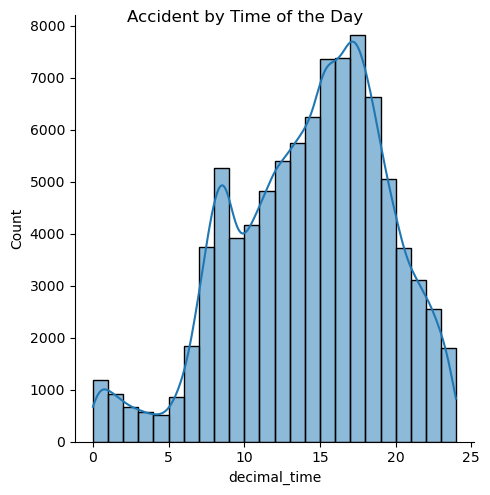

In [105]:
times = sns.displot(a_data, x = 'decimal_time', binwidth = 1, kde = True)
times.fig.suptitle('Accident by Time of the Day') 

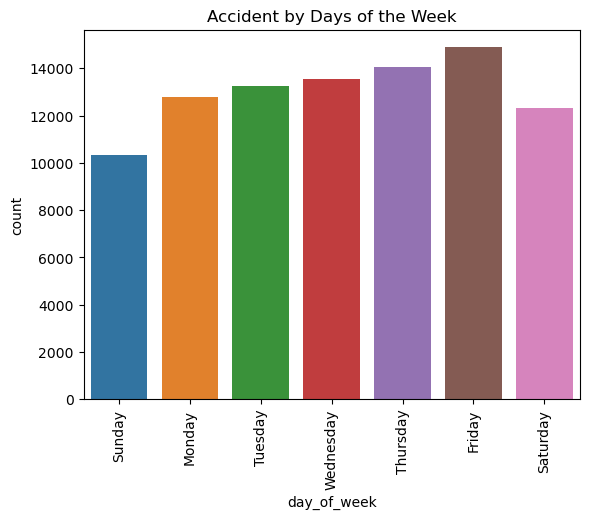

In [106]:
##day of the week relationship


# Create the count plot
days = sns.countplot(x='day_of_week', data=a_data)

# Set the title
days.set_title('Accident by Days of the Week')

# Set the tick labels
days.set_xticklabels(['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'], rotation=90)


# Show the plot
plt.show()

For motorbikes, are there significant hours of the day, and days of the week, on which accidents occur? We suggest a focus on: Motorcycle 125cc and under, Motorcycle over 125cc and up to 500cc, and Motorcycle over 500cc.

In [107]:
# Motorcycle 125cc and under = 03
# Motorcycle over 125cc and up to 500cc = 04
# Motorcycle over 500cc = 05
 
for_motor = cur.execute('''SELECT DISTINCT a.accident_index, a.date, a.day_of_week, a.time, a.accident_severity, v.vehicle_type from accident a
                            JOIN vehicle v on a.accident_index = v.accident_index
                            WHERE a.accident_year = 2020 
                            AND vehicle_type IN (03,04,05)''')    #Filtering out the 2020 data for table accident
for_motor = for_motor.fetchall()

In [108]:
motor_data = pd.DataFrame(for_motor, columns= ['accident_index', 'date', 'day_of_week','time', 'accident_severity', 'vehicle_type'] )     # reading the vehicle data into pandas and

#I will convert the vehicle_type code to the names of the moto
motor_data.loc[(motor_data['vehicle_type'] == 3 ), 'vehicle_type'] = 'Motorcycle 125cc and under'
motor_data.loc[(motor_data['vehicle_type'] == 4 ), 'vehicle_type'] = 'Motorcycle over 125cc and up to 500cc'
motor_data.loc[(motor_data['vehicle_type'] == 5 ), 'vehicle_type'] = 'Motorcycle over 500cc'

motor_data  

,accident_index,date,day_of_week,time,accident_severity,vehicle_type
0,2020010228020,01/01/2020,4,03:25,3,Motorcycle 125cc and under
1,2020010228086,01/01/2020,4,14:00,3,Motorcycle 125cc and under
2,2020010228097,01/01/2020,4,14:37,3,Motorcycle 125cc and under
3,2020010228148,01/01/2020,4,19:05,3,Motorcycle 125cc and under
4,2020010228207,01/01/2020,4,14:29,3,Motorcycle 125cc and under
...,...,...,...,...,...,...
12706,2020991010130,24/12/2020,5,16:30,3,Motorcycle 125cc and under
12707,2020991011809,16/12/2020,4,17:30,3,Motorcycle 125cc and under
12708,2020991012311,28/12/2020,2,17:55,2,Motorcycle 125cc and under
12709,2020991012353,06/08/2020,5,15:45,3,Motorcycle over 125cc and up to 500cc


In [109]:
#I will use the time syntax to get the time in decimal
hour = pd.DatetimeIndex(motor_data['time']).hour
minute = pd.DatetimeIndex(motor_data['time']).minute
#create a new column
motor_data['decimal_time'] = hour + minute/60

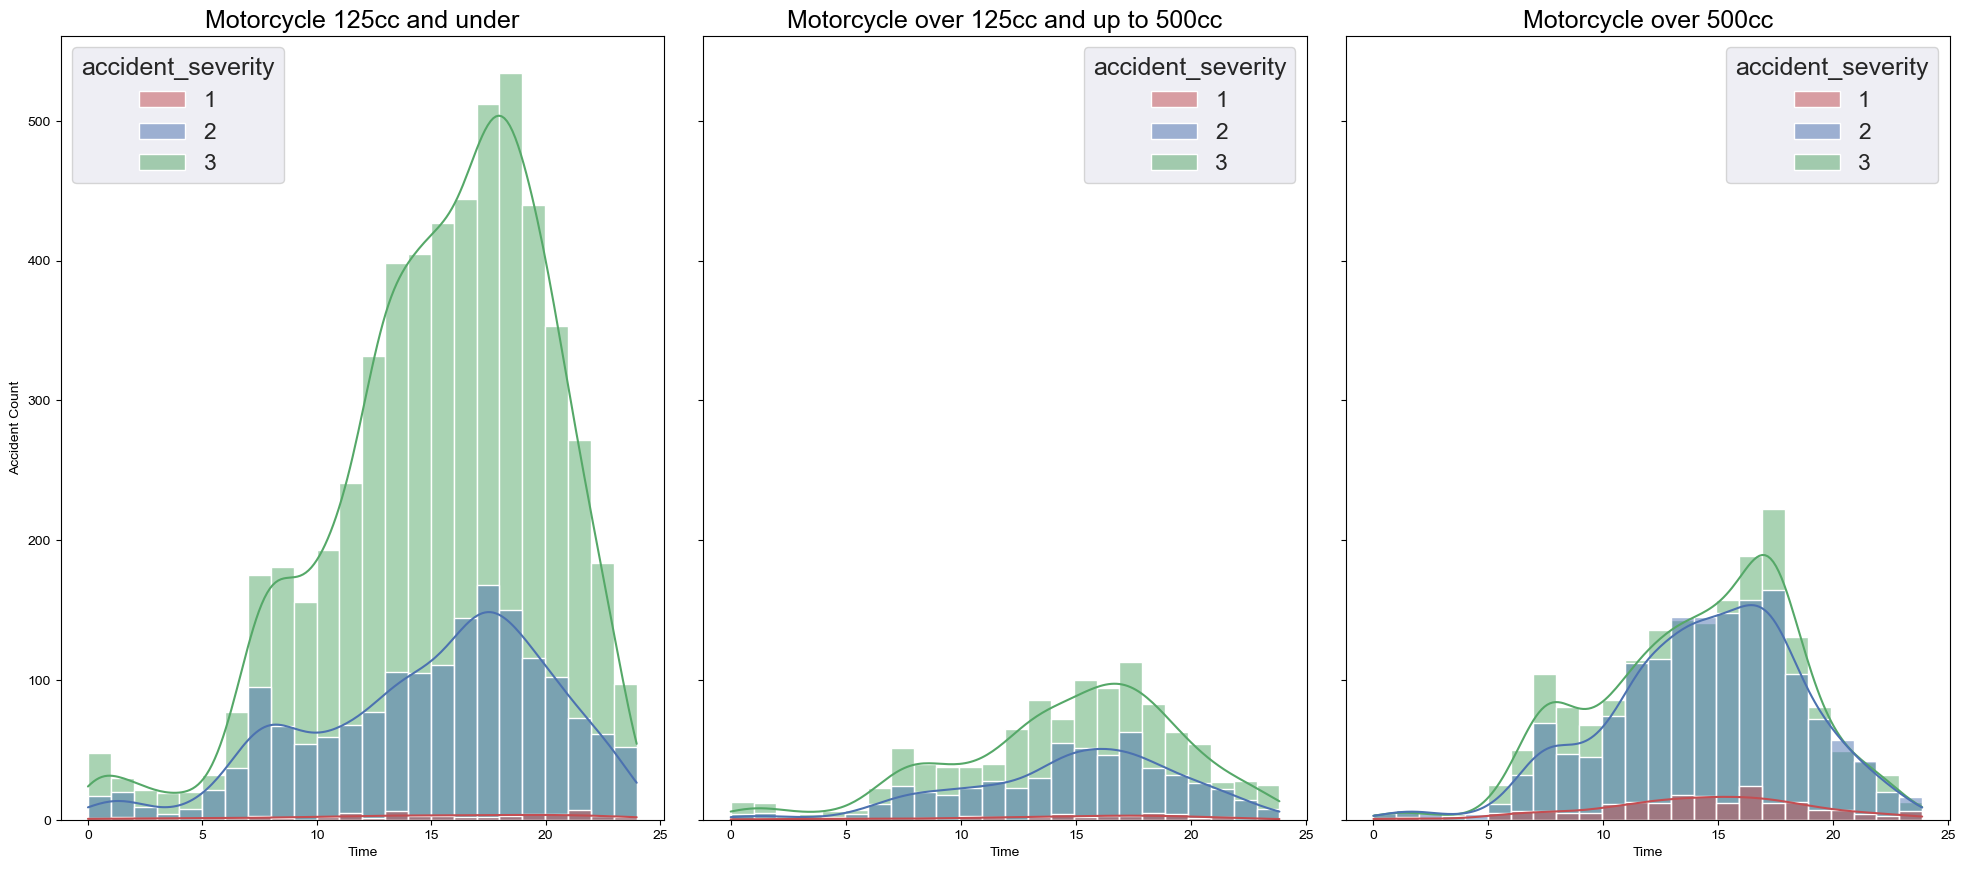

In [110]:
#sns.displot(motor_data, x = 'decimal_time', binwidth = 1, kde = True) 


# Filter the data for the three vehicle types
motorcycle_3 = motor_data[motor_data['vehicle_type'] == 'Motorcycle 125cc and under']
motorcycle_4 = motor_data[motor_data['vehicle_type'] == 'Motorcycle over 125cc and up to 500cc']
motorcycle_5 = motor_data[motor_data['vehicle_type'] == 'Motorcycle over 500cc']

# Create subplots for each vehicle type
fig, axes = plt.subplots(1, 3, figsize=(20, 10), sharey=True)
sns.set(style="white")
sns.set(font_scale=1.5)

# Plot for 'Motorcycle 125cc and under
sns.histplot(data=motorcycle_3, x='decimal_time', bins=24, ax=axes[0], hue = 'accident_severity', palette = ['r', 'b', 'g'], kde=True)
axes[0].set_title('Motorcycle 125cc and under')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Accident Count')

# Plot for Motorcycle over 125cc and up to 500cc
sns.histplot(data=motorcycle_4, x='decimal_time', bins=24, ax=axes[1], hue = 'accident_severity',  kde=True, palette = ['r', 'b', 'g'])
axes[1].set_title('Motorcycle over 125cc and up to 500cc')
axes[1].set_xlabel('Time')

# Plot for Motorcycle over 500cc
sns.histplot(data=motorcycle_5, x='decimal_time', bins=24, ax=axes[2], hue = 'accident_severity',  kde=True, palette = ['r', 'b', 'g'])
axes[2].set_title('Motorcycle over 500cc')
axes[2].set_xlabel('Time')



# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.85)



# Show the plot
plt.show()

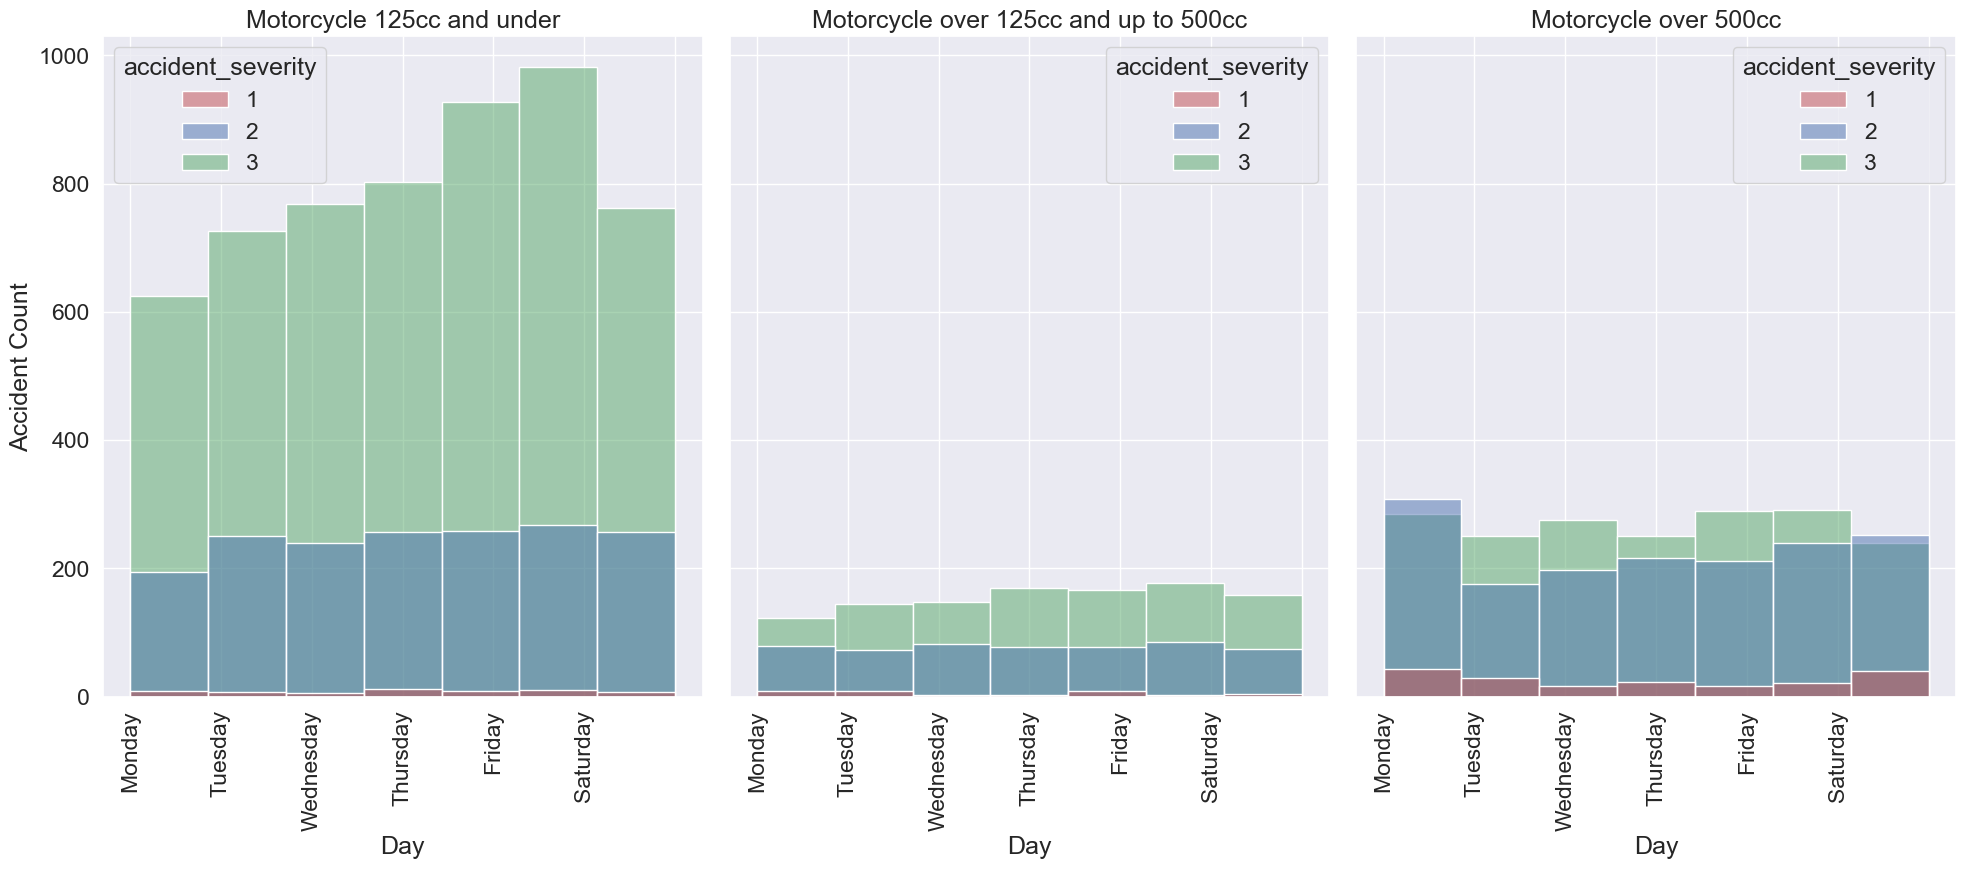

In [111]:
##day of the week relationship
#sns.countplot(x = 'day_of_week', data = motor_data).set(title = 'Motorcycle Accident by Days of the Week')
#sns.displot(motor_data, x = 'decimal_time', binwidth = 1, kde = True) 


# Filter the data for the three vehicle types
motorcycle_3 = motor_data[motor_data['vehicle_type'] == 'Motorcycle 125cc and under']
motorcycle_4 = motor_data[motor_data['vehicle_type'] == 'Motorcycle over 125cc and up to 500cc']
motorcycle_5 = motor_data[motor_data['vehicle_type'] == 'Motorcycle over 500cc']


# Create subplots for each vehicle type
fig, axes = plt.subplots(1, 3, figsize=(20, 10), sharey=True)
sns.set(style="white")
sns.set(font_scale=1.5)


# Plot for 'Motorcycle 125cc and under
sns.histplot(data=motorcycle_3, x='day_of_week', bins=7, ax=axes[0], hue = 'accident_severity', palette = ['r', 'b', 'g'])
axes[0].set_title('Motorcycle 125cc and under')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Accident Count')
axes[0].set_xticklabels(['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'], rotation=90)


# Plot for Motorcycle over 125cc and up to 500cc
sns.histplot(data=motorcycle_4, x='day_of_week', bins=7, ax=axes[1], hue = 'accident_severity', palette = ['r', 'b', 'g'])
axes[1].set_title('Motorcycle over 125cc and up to 500cc')
axes[1].set_xlabel('Day')
axes[1].set_xticklabels(['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'], rotation=90)


# Plot for Motorcycle over 500cc
sns.histplot(data=motorcycle_5, x='day_of_week', bins=7, ax=axes[2], hue = 'accident_severity', palette = ['r', 'b', 'g'])
axes[2].set_title('Motorcycle over 500cc')
axes[2].set_xlabel('Day')
axes[2].set_xticklabels(['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'], rotation=90)


# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.85)



# Show the plot
plt.show()

### Pedestrian Involved in Acccidents

In [112]:
## casualty_class = 3 is pedestrian

for_ped = cur.execute('''SELECT c.accident_index, a.date, a.day_of_week, a.time, c.casualty_severity from accident a
                            JOIN casualty c on a.accident_index = c.accident_index
                            WHERE a.accident_year = 2020 
                            AND casualty_class = 3''')    #Filtering out the 2020 data for table accident
for_ped = for_ped.fetchall()

In [113]:
ped_data = pd.DataFrame(for_ped, columns= ['accident_index', 'date', 'day_of_week','time', 'casualty_severity'] )     # reading the vehicle data into pandas and
ped_data 

,accident_index,date,day_of_week,time,casualty_severity
0,2020010219808,04/02/2020,3,09:00,3
1,2020010220496,27/04/2020,2,13:55,3
2,2020010220496,27/04/2020,2,13:55,3
3,2020010228005,01/01/2020,4,01:25,3
4,2020010228006,01/01/2020,4,01:50,2
...,...,...,...,...,...
14745,2020991023621,10/11/2020,3,10:30,2
14746,2020991023880,14/12/2020,2,17:00,3
14747,2020991024526,17/11/2020,3,12:00,3
14748,2020991029573,13/11/2020,6,15:05,3


In [114]:
hour = pd.DatetimeIndex(ped_data['time']).hour
minute = pd.DatetimeIndex(ped_data['time']).minute
ped_data['decimal_time'] = hour + minute/60

Text(0.5, 0.98, 'Pedestrian Accident by Time of the Day')

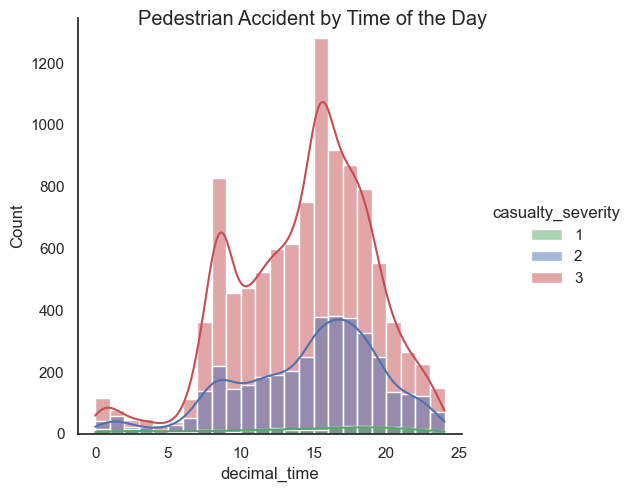

In [115]:
sns.set(style="white")
sns.set_style("white")
days = sns.displot(ped_data, x = 'decimal_time', bins = 24, hue = 'casualty_severity', palette = ['g', 'b', 'r'], kde = True) 
days.fig.suptitle('Pedestrian Accident by Time of the Day')


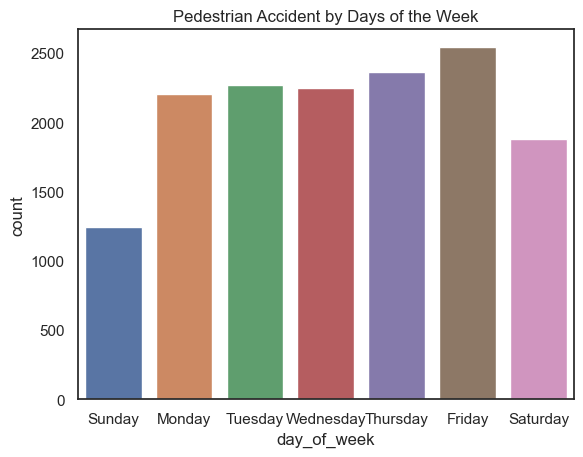

In [116]:
##day of the week relationship

dy = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
sns.countplot(x = 'day_of_week', data = ped_data).set(title = 'Pedestrian Accident by Days of the Week', xticklabels = dy)
sns.set(font_scale=1.0)
plt.show()


In [117]:
vc_data[vc_data['casualty_type'] == 3]['age_of_casualty'].mean()

30.14523774255666

### Feature Selection

I will like to select the most important features to work with subsequently as there are so many features in the dataset and it is confusing which ones are more important in relation to accident analysis. I will use the univariate feature selection and the correlation analysis to determine that

In [118]:
all_ac = pd.merge(a_data, vc_data, on ='accident_reference')

In [119]:
#I will remove duplicated columns like accident index and vehicle reference
all_ac = all_ac.loc[:, ~all_ac.columns.duplicated()]

In [120]:
y = all_ac['accident_severity'] # creating the target variable

In [121]:
x = all_ac.drop(['accident_severity','did_police_officer_attend_scene_of_accident'], axis = 1)

In [122]:
x  = x.select_dtypes([np.number])

In [123]:
#Generate selector to select the best features
selector = SelectKBest(f_classif, k=20)
selector.fit(x, y)

SelectKBest(k=20)

In [124]:
mask = selector.get_support() # mask gets the 
names = selector.feature_names_in_[mask]
scores = selector.scores_[mask]

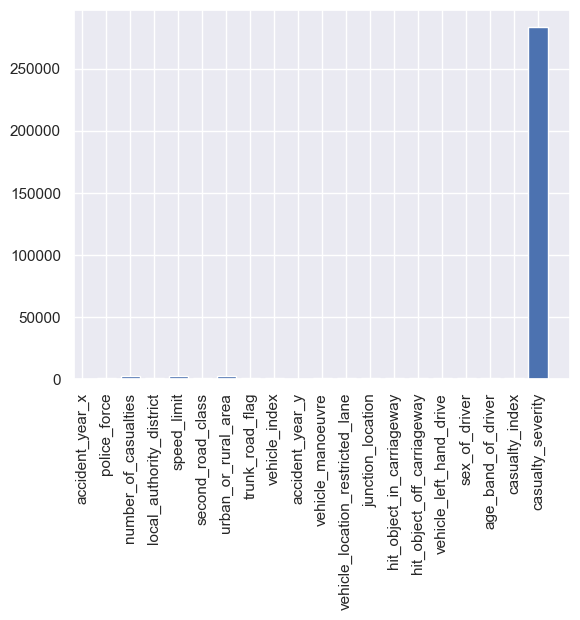

In [125]:
#plot the most important features
plt.bar(names, scores)
plt.xticks(rotation = "vertical")
plt.show()

In [126]:
correlation = x.corrwith(y)



sort = correlation.abs().sort_values(ascending=False)
top_15 = sort.nlargest(20).index

print(top_15)

Index(['casualty_severity', 'speed_limit', 'number_of_casualties',
       'urban_or_rural_area', 'police_force', 'local_authority_district',
       'vehicle_index', 'casualty_index', 'hit_object_in_carriageway',
       'vehicle_location_restricted_lane', 'hit_object_off_carriageway',
       'vehicle_left_hand_drive', 'sex_of_driver', 'age_band_of_driver',
       'junction_location', 'second_road_class', 'trunk_road_flag',
       'location_northing_osgr', 'latitude', 'driver_home_area_type'],
      dtype='object')


In [239]:
# % of accidents in car
len(v_data[v_data['vehicle_type']==9])/len(v_data)

#
len(a_data[a_data['urban_or_rural_area']==1])/len(a_data)

0.6769482121514491

<class 'pandas.core.frame.DataFrame'>
Int64Index: 220435 entries, 0 to 220434
Data columns (total 81 columns):
 #   Column                                       Non-Null Count   Dtype         
---  ------                                       --------------   -----         
 0   accident_index_x                             220435 non-null  object        
 1   accident_year_x                              220435 non-null  int64         
 2   accident_reference                           220435 non-null  object        
 3   location_easting_osgr                        220435 non-null  float64       
 4   location_northing_osgr                       220435 non-null  float64       
 5   longitude                                    220435 non-null  float64       
 6   latitude                                     220435 non-null  float64       
 7   police_force                                 220435 non-null  int64         
 8   accident_severity                            220435 non-null  in

## Apriori Algorithm

Using the apriori algorithm, I will explore the impact of some selected variables(from the feature selection above) on accident severity. I will have create a dataframe with the variables, then encode it using the one hot encoding method to enable me run the apriori algorithm

In [128]:
columns = ['accident_severity', 'day_of_week', 'first_road_class', 'road_type', 'junction_detail', 'junction_control', 'second_road_class', 'light_conditions', 'weather_conditions', 'urban_or_rural_area', 'vehicle_type', 'sex_of_driver', 'casualty_type', 'casualty_severity' ]
apr_accident  = all_ac[columns]

In [129]:
 apr_acc = pd.get_dummies(apr_accident, columns = columns)

In [130]:
apr_acc.head()

,accident_severity_1,accident_severity_2,accident_severity_3,day_of_week_1,day_of_week_2,day_of_week_3,day_of_week_4,day_of_week_5,day_of_week_6,day_of_week_7,...,casualty_type_20,casualty_type_21,casualty_type_22,casualty_type_23,casualty_type_90,casualty_type_97,casualty_type_98,casualty_severity_1,casualty_severity_2,casualty_severity_3
0,0,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,0,1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,0,0,1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,0,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [131]:
#apriori algorithm
a_support =  apriori(apr_acc, use_colnames =True) # define the support for the algorithm. 

rules = association_rules(a_support, metric = "lift", min_threshold=0.5) 

# Set thresholds for metrics
minimum_confidence = 0.9
minimum_lift = 1.2
minimum_support = 0.5

# Filter rules based on threshols set above
selected_rules = rules[(rules['confidence'] > minimum_confidence) & (rules['lift'] > minimum_lift) & (rules['support'] > minimum_support)]

# Sort the rules by lift in descending order
selected_rules = selected_rules.sort_values(by='lift', ascending=False)

In [132]:
selected_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction,zhangs_metric
34,(casualty_type_9),(vehicle_type_9),0.588255,0.718266,0.535087,0.909618,1.266408,0.112564,3.117149,0.510911
61,"(urban_or_rural_area_1, casualty_severity_3)",(accident_severity_3),0.546964,0.777445,0.525701,0.961126,1.236263,0.100467,5.725092,0.421845
49,"(light_conditions_1, casualty_severity_3)",(accident_severity_3),0.592510,0.777445,0.558282,0.942233,1.211961,0.097639,3.852612,0.429191
55,"(weather_conditions_1, casualty_severity_3)",(accident_severity_3),0.642961,0.777445,0.604246,0.939787,1.208816,0.104380,3.696157,0.483824
10,(accident_severity_3),(casualty_severity_3),0.777445,0.828067,0.777445,1.000000,1.207631,0.133668,inf,0.772539
11,(casualty_severity_3),(accident_severity_3),0.828067,0.777445,0.777445,0.938867,1.207631,0.133668,3.640483,1.000000
42,"(road_type_6, accident_severity_3)",(casualty_severity_3),0.549137,0.828067,0.549137,1.000000,1.207631,0.094415,inf,0.381341
48,"(light_conditions_1, accident_severity_3)",(casualty_severity_3),0.558282,0.828067,0.558282,1.000000,1.207631,0.095987,inf,0.389237
54,"(weather_conditions_1, accident_severity_3)",(casualty_severity_3),0.604246,0.828067,0.604246,1.000000,1.207631,0.103890,inf,0.434444
60,"(urban_or_rural_area_1, accident_severity_3)",(casualty_severity_3),0.525701,0.828067,0.525701,1.000000,1.207631,0.090385,inf,0.362499


In [133]:
severity_1 = selected_rules[(selected_rules['consequents'] == {'accident_severity_1'}) | (selected_rules['consequents'] == {'accident_severity_2'}) | (selected_rules['consequents'] == {'accident_severity_3'}) ] 
#severity_2 = rules[rules['consequents'] == {'accident_severity_2'}]
#severity_3 = rules[rules['consequents'] == {'accident_severity_3'}]

In [134]:
severity_1

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction,zhangs_metric
61,"(urban_or_rural_area_1, casualty_severity_3)",(accident_severity_3),0.546964,0.777445,0.525701,0.961126,1.236263,0.100467,5.725092,0.421845
49,"(light_conditions_1, casualty_severity_3)",(accident_severity_3),0.592510,0.777445,0.558282,0.942233,1.211961,0.097639,3.852612,0.429191
55,"(weather_conditions_1, casualty_severity_3)",(accident_severity_3),0.642961,0.777445,0.604246,0.939787,1.208816,0.104380,3.696157,0.483824
11,(casualty_severity_3),(accident_severity_3),0.828067,0.777445,0.777445,0.938867,1.207631,0.133668,3.640483,1.000000
43,"(road_type_6, casualty_severity_3)",(accident_severity_3),0.586953,0.777445,0.549137,0.935572,1.203394,0.092813,3.454334,0.409195
67,"(vehicle_type_9, casualty_severity_3)",(accident_severity_3),0.611387,0.777445,0.571302,0.934437,1.201934,0.095983,3.394524,0.432325


In [135]:
#to check why only severity 3 featured
severity_3 = len(all_ac[all_ac['accident_severity'] == 3])
severity_3_freq = severity_3/len(all_ac)
severity_3_freq

0.7774445981808696

## Accidents in our Region

We need to understand the code for our region. In the police force code, Humberside is coded as 16 as seen in the STAT20 Form. I will query the accidents in our region directly from the database and filter out only accidents that occured in the Kingston Upon Hull, East riding of Yorkshire or regions under police force code 16. This is to ensure that we capture all the accidents in the region

In [136]:
region = cur.execute('''SELECT a.longitude, a.latitude from accident a
                            JOIN lsoa l ON a.lsoa_of_accident_location = l.lsoa01cd
                            WHERE a.accident_year = 2020
                            AND l.lsoa01nm LIKE '%Kingston upon Hull%'
                            OR  l.lsoa01nm LIKE '%East Riding of Yorkshire%'
                            OR a.police_force = 16 
                           ''')  
region = region.fetchall()


In [137]:
reg_data = pd.DataFrame(region, columns= ['longitude', 'latitude'] ) #convert the output to dataframe
len(reg_data)

8395

In [138]:
reg = pd.DataFrame(reg_data).to_numpy() # convert the dataframe to numpy toenable us run the clustering analysis

In [139]:
sc = StandardScaler() #to scale the data in preparation for the clustering
sc.fit_transform(reg)

array([[-0.04350735,  0.19427046],
       [ 0.51756842,  1.05076369],
       [ 1.43494208, -1.09472449],
       ...,
       [ 0.33619077,  0.46853276],
       [-1.43443604, -1.08039529],
       [ 0.18718098,  0.17655899]])

#### K-Means Clustering
I will first use the elbow method to determine the optimal number of clusters for the clustering

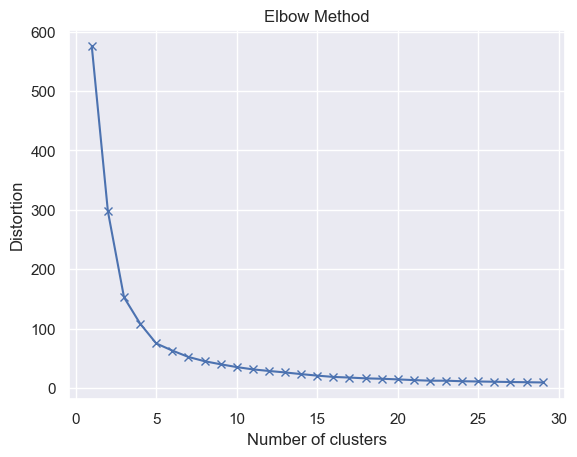

In [140]:
#Elbow methodof clustering
distortions = []
K = range(1, 30)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=30)
    kmeans.fit(reg)
    distortions.append(kmeans.inertia_)
plt.plot(K, distortions, 'bx-')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.title('Elbow Method')
plt.show()

In [141]:
## The number of clusters from the Humberside region is chosen from the elbow method above
kmeans = KMeans(n_clusters = 5)
kmeans.fit(reg) #fit the data into kmeans

KMeans(n_clusters=5)

In [142]:
# after predicting, we will use the labels to predict
labels = kmeans.predict(reg) 
centroids = kmeans.cluster_centers_

In [143]:
labels # print the labels

array([2, 2, 1, ..., 2, 3, 2])

In [144]:
centroids # print the centroids

array([[-0.8180069 , 53.8061327 ],
       [-0.08883301, 53.5746709 ],
       [-0.36426053, 53.7570034 ],
       [-0.64931188, 53.58397018],
       [-0.29276232, 54.03575406]])

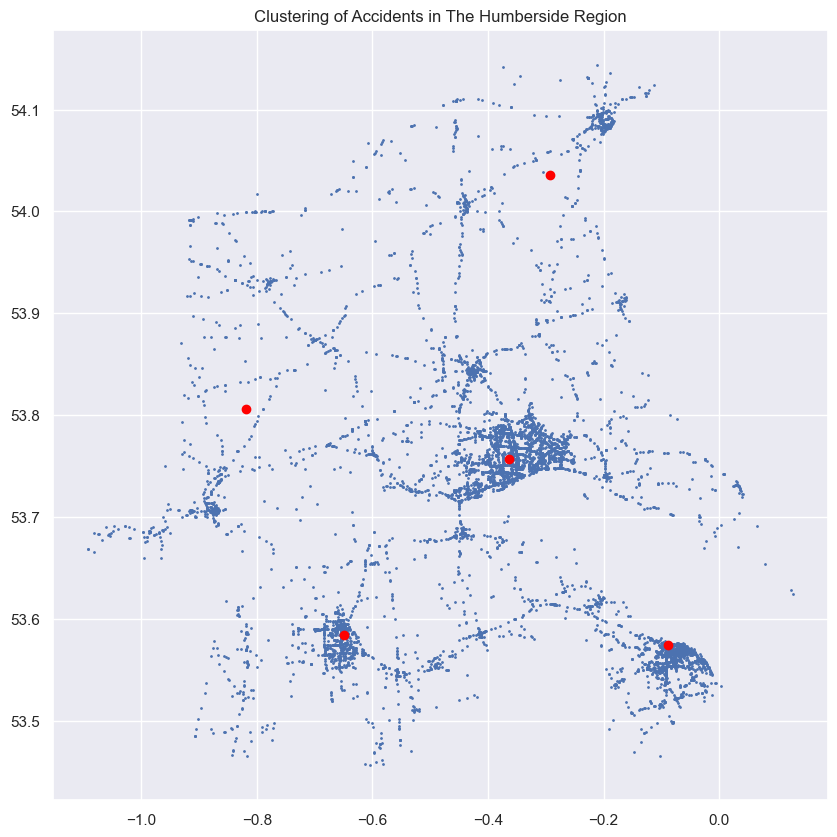

In [145]:
#plot the clustering result on a map using the longitude and latitude

fig = plt.figure(figsize = (10,10))
colmap = {1:'red', 2:'yellow', 3:'green', 4:'brown', 5: 'blue', 6:'purple'}
colors = list(map(lambda x: colmap, labels))
plt.scatter(reg_data['longitude'], reg_data['latitude'],  s = 1 )
plt.scatter(centroids[:,0], centroids[:,1], color = 'red')
plt.title('Clustering of Accidents in The Humberside Region')
plt.show()

# fig = plt.figure(figsize = (5,5))
# #colmap = {1:'r', 2: 'g', 3: 'b'}
# #colors = list(map(lambda x: colmap[x+1], labels))

# plt.scatter(reg_data[:,0], reg_data[:,1])#, c = labels)


# plt.scatter(centroids[:,0],  centroids[:,1], color = 'red')
# plt.show()

### Clustering of Speed Limit and Weather Conditions

I will perform clustering with speed limit and weather conditions as my variables. First, I will create a dataframe to work with

In [146]:
humberside = cur.execute('''SELECT a.speed_limit, a.weather_conditions from accident a
                            JOIN lsoa l ON a.lsoa_of_accident_location = l.lsoa01cd
                            WHERE a.accident_year = 2020
                            AND l.lsoa01nm LIKE '%Kingston upon Hull%'
                            OR  l.lsoa01nm LIKE '%East Riding of Yorkshire%'
                            OR a.police_force = 16 
                           ''')  
humberside = humberside.fetchall()

In [147]:
spw_data = pd.DataFrame(humberside, columns= ['speed_limit', 'weather_conditions'] ) #convert the output to dataframe
len(spw_data)

8395

In [148]:
spw = pd.DataFrame(spw_data).to_numpy() # convert the dataframe to numpy toenable us run the clustering analysis

In [149]:
sc = StandardScaler() #to scale the data in preparation for the clustering
sc.fit_transform(spw)

array([[-0.53143446, -0.30153265],
       [ 1.77857191, -0.30153265],
       [-0.53143446,  0.33353172],
       ...,
       [-0.53143446, -0.30153265],
       [ 2.54857404, -0.30153265],
       [-0.53143446, -0.30153265]])

#### K-Means Clustering
I will first use the elbow method to determine the optimal number of clusters for the clustering

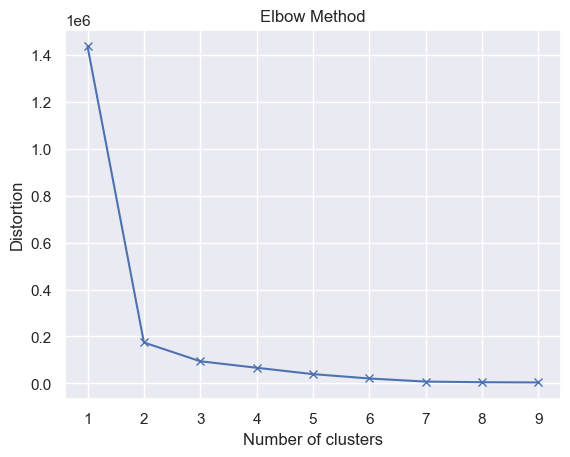

In [150]:
#Elbow method of clustering
distortions = []
K = range(1, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=30)
    kmeans.fit(spw)
    distortions.append(kmeans.inertia_)
plt.plot(K, distortions, 'bx-')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.title('Elbow Method')
plt.show()

In [151]:
## The number of clusters 
kmeans = KMeans(n_clusters = 6) #the count of speed limit available in the data
kmeans.fit(spw) #fit the data into kmeans

KMeans(n_clusters=6)

In [152]:
# after predicting, we will use the labels to predict
labels = kmeans.predict(spw) 
centroids = kmeans.cluster_centers_

In [153]:
labels # print the labels

array([2, 1, 2, ..., 2, 3, 2])

In [154]:
centroids # print the centroids

array([[40.        ,  1.41104294],
       [60.        ,  1.55004352],
       [30.        ,  1.46762843],
       [70.        ,  1.42739726],
       [20.        ,  1.40701754],
       [50.        ,  1.6       ]])

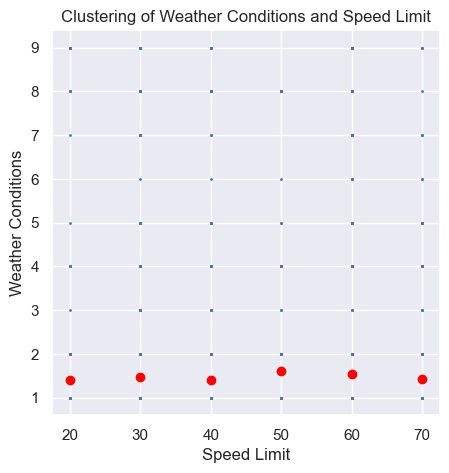

In [155]:
#plot the clustering result on a map using the longitude and latitude

fig = plt.figure(figsize = (5,5))
colmap = {1:'red', 2:'yellow', 3:'green', 4:'brown', 5: 'blue', 6:'purple'}
colors = list(map(lambda x: colmap, labels))
plt.scatter(spw[:,0], spw[:,1],  s = 1 )
plt.scatter(centroids[:,0], centroids[:,1], color = 'red')

plt.xlabel('Speed Limit')
plt.ylabel('Weather Conditions')
plt.title('Clustering of Weather Conditions and Speed Limit')
plt.show()



### Outlier Detection Method - Interquartile

In [156]:
#Assign the selected columns to variables
age = vc_data['age_of_driver']
age_c = vc_data['age_of_casualty']
age_v = vc_data['age_of_vehicle']

In [157]:
# Convert the variables to numpy array
age_py = pd.DataFrame(age).to_numpy()
age_cpy = pd.DataFrame(age_c).to_numpy()
age_vpy = pd.DataFrame(age_v).to_numpy()

In [158]:
# calculate interquartile range for age of driver
q75, q25 = np.percentile(age_py, [75, 25])
iqr = q75 - q25
print(iqr)
print(q25 - 1.5*iqr, q75 + 1.5 * iqr)

22.0
-5.0 83.0


In [159]:
# To see drivers with ages greater than the higher interquartile range
out_d = vc_data[vc_data['age_of_driver'] > 86]
out_d

,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,...,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_home_area_type,casualty_imd_decile,vc_id
136,681827,2020010228276,2020,010228276,1,9,0,18,1,5,...,3,0,0,0,0,0,9,1,3,202001022827611
475,682108,2020010228787,2020,010228787,2,9,0,99,9,9,...,3,0,0,0,0,0,9,1,6,202001022878721
2173,683518,2020010231441,2020,010231441,2,9,0,18,3,7,...,3,0,0,0,0,0,9,1,6,202001023144121
2479,683787,2020010231896,2020,010231896,1,9,0,5,5,1,...,3,1,1,0,0,0,0,1,5,202001023189611
2938,684179,2020010232619,2020,010232619,1,9,0,18,2,6,...,3,0,0,0,0,0,9,1,10,202001023261911
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219116,848123,2020990998726,2020,990998726,1,9,0,18,3,7,...,3,0,0,0,0,0,9,1,9,202099099872611
219117,848123,2020990998726,2020,990998726,1,9,0,18,3,7,...,3,0,0,0,0,0,9,1,1,202099099872612
219663,848535,2020991004453,2020,991004453,1,9,0,18,5,1,...,2,4,1,0,0,0,0,-1,-1,202099100445311
219673,848542,2020991004522,2020,991004522,1,9,0,9,3,1,...,2,0,0,0,0,0,9,3,8,202099100452211


In [160]:
out_d['age_of_driver'].value_counts()

#it is not unusual to have drivers above 89 years in the UK
#https://www.mirror.co.uk/news/politics/number-100-year-olds-driving-26840283

87     235
88     177
89     153
90     134
91      69
92      69
93      47
94      18
95      13
96      12
97       4
98       4
99       3
100      1
Name: age_of_driver, dtype: int64

In [161]:
# calculate interquartile range for age of vehicle
q75, q25 = np.percentile(age_vpy, [75, 25])
iqr = q75 - q25
print(iqr)
print(q25 - 1.5*iqr, q75 + 1.5 * iqr)

8.0
-7.0 25.0


In [162]:
# To see vehicles with ages greater than the higher interquartile range
out_v = vc_data[vc_data['age_of_vehicle'] > 25]
out_v

# it is not unusual to have a car older than 29 years old. (https://www.gov.uk/historic-vehicles)

,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,...,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_home_area_type,casualty_imd_decile,vc_id
855,682399,2020010229391,2020,010229391,2,9,0,18,7,3,...,3,0,0,0,0,0,9,1,3,202001022939121
997,682519,2020010229602,2020,010229602,2,9,0,4,5,1,...,3,0,0,0,0,0,1,1,9,202001022960221
1047,682563,2020010229701,2020,010229701,1,9,0,99,9,9,...,3,0,0,0,0,0,9,1,2,202001022970111
2199,683538,2020010231465,2020,010231465,2,90,0,18,7,3,...,3,0,0,0,0,0,9,1,3,202001023146521
2955,684188,2020010232639,2020,010232639,2,9,0,16,7,2,...,2,0,0,0,0,0,19,1,9,202001023263921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218319,847514,2020990989069,2020,990989069,2,2,0,18,5,1,...,2,0,0,0,0,0,2,1,2,202099098906921
218614,847736,2020990992686,2020,990992686,2,17,0,10,1,5,...,3,0,0,0,0,0,5,3,5,202099099268621
218825,847896,2020990994835,2020,990994835,1,9,0,2,0,0,...,3,0,0,0,0,0,1,1,10,202099099483511
219503,848420,2020991002465,2020,991002465,2,90,0,18,5,1,...,3,0,0,0,0,0,19,1,1,202099100246521


In [163]:
out_v['age_of_vehicle'].value_counts()

26    101
28     92
27     81
30     62
29     60
31     57
32     42
33     20
34     19
42     17
39     16
36     16
50     12
44     11
41     11
38      9
53      8
43      8
48      8
57      8
35      7
61      6
60      6
56      5
40      5
45      4
54      4
51      4
49      4
58      3
63      3
52      3
67      3
37      3
46      3
88      2
55      2
86      2
92      1
84      1
62      1
66      1
78      1
47      1
96      1
68      1
64      1
93      1
Name: age_of_vehicle, dtype: int64

In [164]:
# To see vehicles with ages lower than the lower interquartile range
out_v_low = v_data[v_data['age_of_vehicle'] < -7]
out_v_low

,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,...,journey_purpose_of_driver,sex_of_driver,age_of_driver,age_band_of_driver,engine_capacity_cc,propulsion_code,age_of_vehicle,generic_make_model,driver_imd_decile,driver_home_area_type


As seen above, there are no vehicles below the lower interquartile range

In [165]:
# calculate interquartile range for age of driver
q75, q25 = np.percentile(age_cpy, [75, 25])
iqr = q75 - q25
print(iqr)
print(q25 - 1.5*iqr, q75 + 1.5 * iqr)

26.0
-15.0 89.0


In [166]:
# To see drivers with ages greater than the higher interquartile range
out_c = vc_data[vc_data['age_of_casualty'] > 89]
out_c

,vehicle_index,accident_index,accident_year,accident_reference,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,...,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_home_area_type,casualty_imd_decile,vc_id
934,682469,2020010229497,2020,010229497,1,11,0,7,1,3,...,2,4,1,0,0,0,0,1,3,202001022949711
1213,682711,2020010229955,2020,010229955,1,8,0,5,5,1,...,2,5,3,0,0,0,0,1,8,202001022995511
2056,683422,2020010231303,2020,010231303,1,11,0,18,1,5,...,3,0,0,0,3,0,11,1,10,202001023130311
2938,684179,2020010232619,2020,010232619,1,9,0,18,2,6,...,3,0,0,0,0,0,9,1,10,202001023261911
2940,684180,2020010232619,2020,010232619,2,9,0,2,0,0,...,3,0,0,0,0,0,9,1,10,202001023261921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217079,846601,2020990976734,2020,990976734,1,17,0,10,2,8,...,3,0,0,1,0,0,9,3,6,202099097673411
217080,846602,2020990976734,2020,990976734,2,9,0,18,8,4,...,3,0,0,1,0,0,9,3,6,202099097673421
219111,848118,2020990998622,2020,990998622,1,9,0,17,4,1,...,1,1,1,0,0,0,0,1,10,202099099862211
219663,848535,2020991004453,2020,991004453,1,9,0,18,5,1,...,2,4,1,0,0,0,0,-1,-1,202099100445311


In [167]:
out_c['age_of_casualty'].value_counts()

#it is not unusual to have drivers above 89 years in the UK
#https://www.mirror.co.uk/news/politics/number-100-year-olds-driving-26840283

90    151
91    106
92     77
93     58
95     34
94     31
96     20
98     13
97      4
99      3
Name: age_of_casualty, dtype: int64

## Classification and Prediction - Accident Data

I will create a series of labels, which have True for fatal accidents and False for non-fatal accidents. From the STATS20 Form, Accident severity is labelled as 1 - Fatal, while the other classes 2 - serious and 3 - slight are non fatal. I will do thos for only the accident data


In [168]:
y_label = a_data['accident_severity']==1 # create a true/false label

In [169]:
#\i will create a balanced data as we have more non fatal accidents
balanced_acc, y_balanced = RandomUnderSampler().fit_resample(a_data, y_label )

Now we have balanced dataset. I will then carry out feature selection on the balanced data

In [170]:
y = y_balanced # creating the target variable with the balanced data

I will remove did_police_officer_attend_scene_of_accident column. Police officers are more likely to attend an accident if it is fatal, and we are interested in the causes of fatal accidents not how the police respond after the event. 

In [171]:
x = balanced_acc.drop(['accident_severity','did_police_officer_attend_scene_of_accident'], axis = 1)

In [172]:
x  = x.select_dtypes([np.number])

In [173]:
#Generate selector to select the best features
selector = SelectKBest(f_classif, k=10)
selector.fit(x, y)

SelectKBest()

In [174]:
mask = selector.get_support() #I will create a mask which will select the best features 
#then create variables for the names and scores attributes
names = selector.feature_names_in_[mask]
scores = selector.scores_[mask]

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

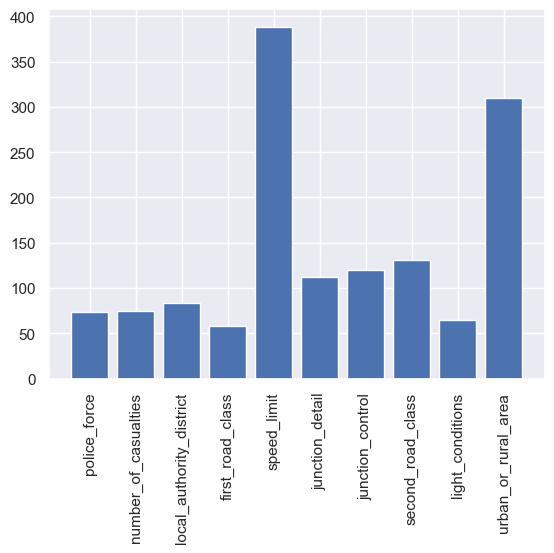

In [175]:
#I will plot the most important features
plt.bar(names, scores)
plt.xticks(rotation = "vertical")

## Decision Tree Classifier - Accident Data Simple model

First I will use a Decision Tree Classifier in classifying and predicting severity of an accident given the conditions in which it occured

In [176]:
#Train Test Split - to get the training data and the test data

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [177]:
#I will create a decisiontree classifier object with minimum samples in leaf nodes of 100
tree = DecisionTreeClassifier()

In [178]:
#Train the Model

tree.fit(x_train, y_train)

DecisionTreeClassifier()

In [179]:
#predict withthe test data
y_pred = tree.predict(x_test)

In [180]:
# round the result to 2 decimal place
round_tree = round(tree.score(x_train, y_train) * 100, 2)
print(round_tree)

100.0


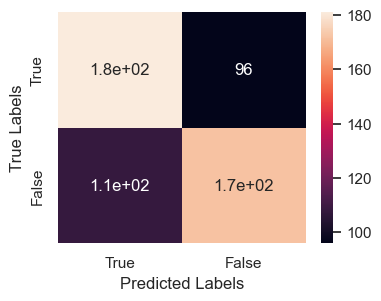

In [181]:
#plot the confusion matrix
plt.figure(figsize = (4,3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, xticklabels=['True', 'False'], yticklabels=['True', 'False'])

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [182]:
# print classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.63      0.65      0.64       277
        True       0.64      0.61      0.63       280

    accuracy                           0.63       557
   macro avg       0.63      0.63      0.63       557
weighted avg       0.63      0.63      0.63       557



#### With Cross VAlidation and Minimum Sample Leaf

In [183]:
#I will create a decisiontree classifier object with minimum samples in leaf nodes of 100
tree = DecisionTreeClassifier(min_samples_leaf=100)

In [184]:
# I will run cross validation on the training data to prevent over fitting
results_tree = cross_validate(tree, x_train, y_train, cv=10, scoring='accuracy', return_estimator = True)

In [185]:
# I will check the result keys to see which coresponds to the score of my cross validation
results_tree.keys()

dict_keys(['fit_time', 'score_time', 'estimator', 'test_score'])

In [186]:
#print the result of cross validation
results_tree['test_score']

array([0.65470852, 0.70852018, 0.66816143, 0.70403587, 0.72197309,
       0.67567568, 0.66216216, 0.66216216, 0.68918919, 0.62162162])

In [187]:
#Train the Model

tree.fit(x_train, y_train)

DecisionTreeClassifier(min_samples_leaf=100)

In [188]:
#predict withthe test data
y_pred = tree.predict(x_test)

In [189]:
# round the result to 2 decimal place
round_tree = round(tree.score(x_train, y_train) * 100, 2)
print(round_tree)

70.16


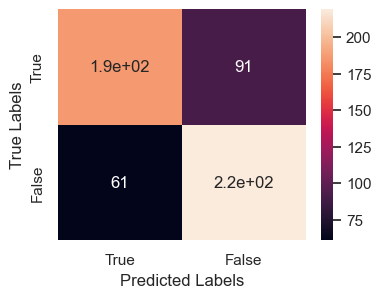

In [190]:
#plot the confusion matrix
plt.figure(figsize = (4,3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, xticklabels=['True', 'False'], yticklabels=['True', 'False'])

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [191]:
# print classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.75      0.67      0.71       277
        True       0.71      0.78      0.74       280

    accuracy                           0.73       557
   macro avg       0.73      0.73      0.73       557
weighted avg       0.73      0.73      0.73       557



### Feature Importance

In [192]:
importance = pd.DataFrame(np.array([tree.feature_names_in_, 
                                   tree.feature_importances_]
                                  ).T,
                         columns =['Features', 'Importance'])

In [193]:
importance.sort_values('Importance', ascending = False)

,Features,Importance
13,speed_limit,0.453686
6,number_of_vehicles,0.281293
27,decimal_time,0.05758
16,second_road_class,0.048447
7,number_of_casualties,0.048001
3,longitude,0.033815
2,location_northing_osgr,0.030701
20,light_conditions,0.020181
22,road_surface_conditions,0.012423
4,latitude,0.007672


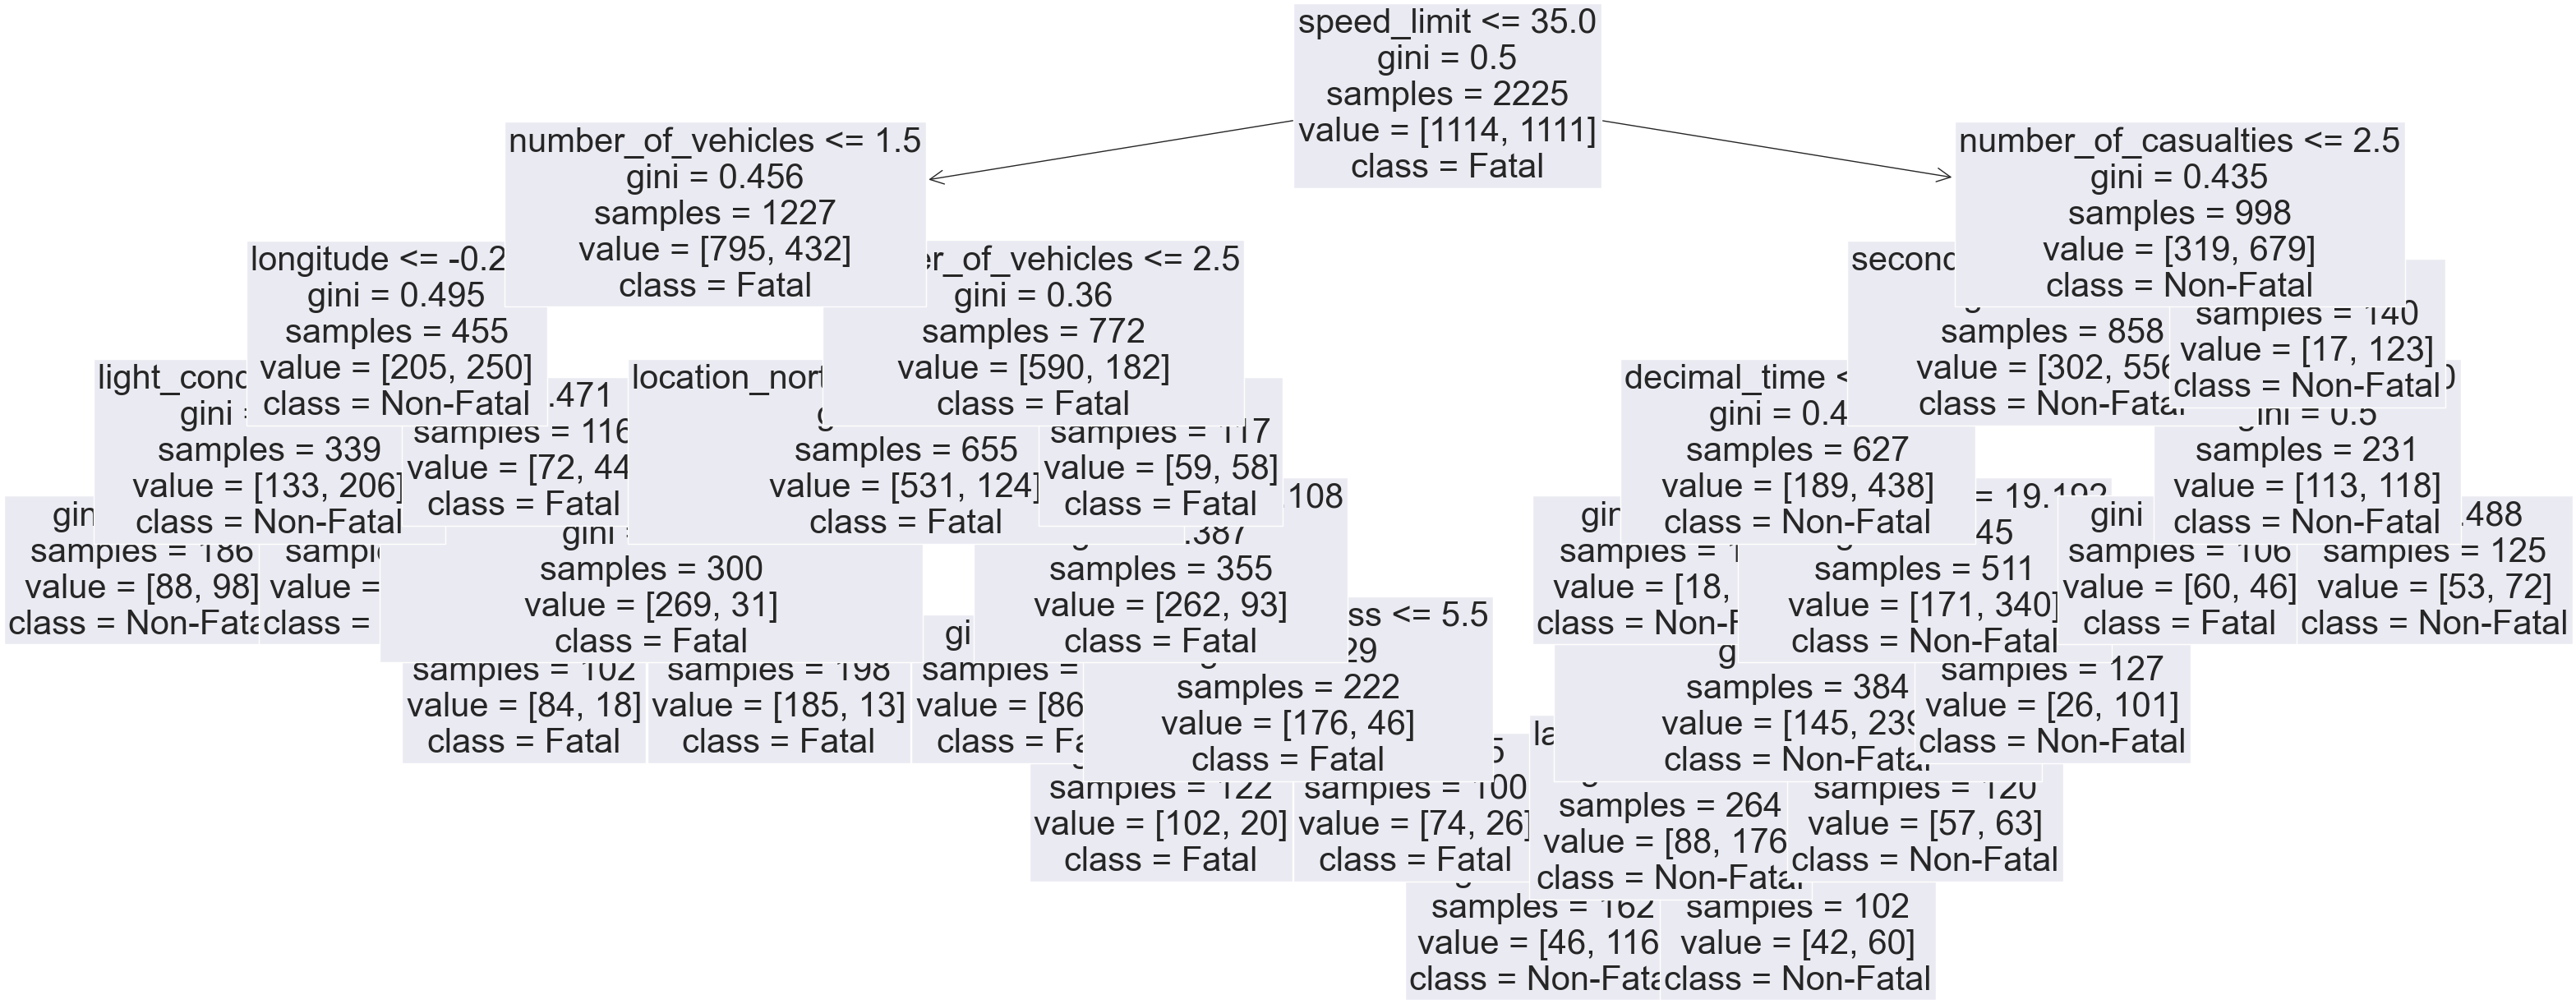

In [194]:
plt.figure(figsize=(40,15))
plot_tree(tree, feature_names = tree.feature_names_in_,
         class_names = ['Fatal', 'Non-Fatal'], fontsize =30)
plt.show()

## Classification and Prediction - Merged Data Set

I will create a series of labels, which have True for fatal accidents and False for non-fatal accidents. From the STATS20 Form, Accident severity is labelled as 1 - Fatal, while the other classes 2 - serious and 3 - slight are non fatal


In [195]:
all_ac =all_ac.drop_duplicates(['accident_reference'])

In [196]:
y_label = all_ac['accident_severity']==1 # create a true/false label

In [197]:
#\i will create a balanced data as we have more non fatal accidents
balanced_acc, y_balanced = RandomUnderSampler().fit_resample(all_ac, y_label )

Now we have balanced dataset. I will then carry out feature selection on the balanced data

In [198]:
y = y_balanced # creating the target variable with the balanced data

I will remove did_police_officer_attend_scene_of_accident column. Police officers are more likely to attend an accident if it is fatal, and we are interested in the causes of fatal accidents not how the police respond after the event. 

In [199]:
x = balanced_acc.drop(['accident_severity','did_police_officer_attend_scene_of_accident'], axis = 1)

In [200]:
x  = x.select_dtypes([np.number])

In [201]:
#Generate selector to select the best features
selector = SelectKBest(f_classif, k=10)
selector.fit(x, y)

SelectKBest()

In [202]:
mask = selector.get_support() #I will create a mask which will select the best features 
#then create variables for the names and scores attributes
names = selector.feature_names_in_[mask]
scores = selector.scores_[mask]

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

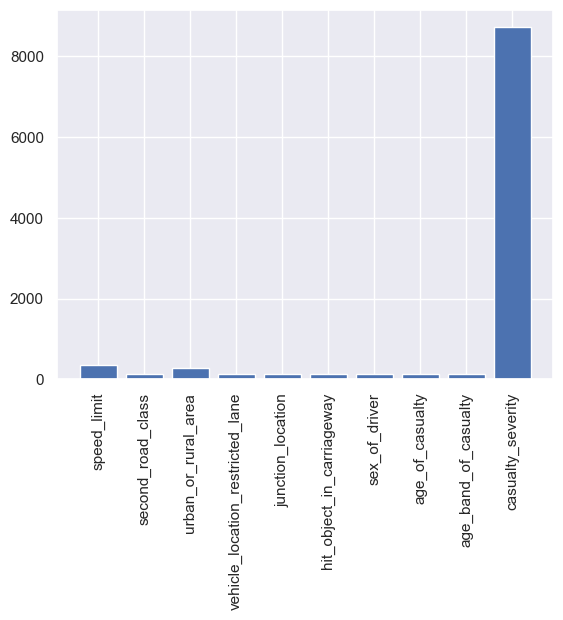

In [203]:
#I will plot the most important features
plt.bar(names, scores)
plt.xticks(rotation = "vertical")

## Simple Decision Tree Classifier

First I will use a Decision Tree Classifier in classifying and predicting severity of an accident given the conditions in which it occured

In [204]:
#Train Test Split - to get the training data and the test data

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [205]:
#I will create a decisiontree classifier object with minimum samples in leaf nodes of 100
tree = DecisionTreeClassifier()

In [206]:
#Train the Model

tree.fit(x_train, y_train)

DecisionTreeClassifier()

In [207]:
#predict withthe test data
y_pred = tree.predict(x_test)

In [208]:
# round the result to 2 decimal place
round_tree = round(tree.score(x_train, y_train) * 100, 2)
print(round_tree)

100.0


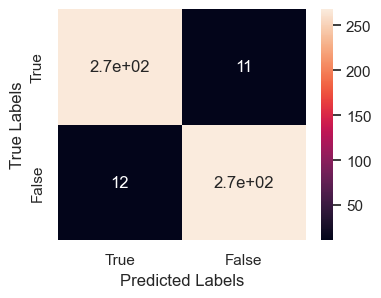

In [209]:
#plot the confusion matrix
plt.figure(figsize = (4,3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, xticklabels=['True', 'False'], yticklabels=['True', 'False'])

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [210]:
# print classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.96      0.96      0.96       277
        True       0.96      0.96      0.96       280

    accuracy                           0.96       557
   macro avg       0.96      0.96      0.96       557
weighted avg       0.96      0.96      0.96       557



#### Hyperparameter Tuning

In [211]:
#I will create a decisiontree classifier object with minimum samples in leaf nodes of 100
tree = DecisionTreeClassifier(min_samples_leaf=100)

In [212]:
# I will run cross validation on the training data to prevent over fitting
results_tree = cross_validate(tree, x_train, y_train, cv=10, scoring='accuracy', return_estimator = True)

In [213]:
# I will check the result keys to see which coresponds to the score of my cross validation
results_tree.keys()

dict_keys(['fit_time', 'score_time', 'estimator', 'test_score'])

In [214]:
#print the result of cross validation
results_tree['test_score']

array([0.93721973, 0.97309417, 0.97309417, 0.98206278, 0.95964126,
       0.93693694, 0.95045045, 0.96396396, 0.95045045, 0.93693694])

In [215]:
#Train the Model

tree.fit(x_train, y_train)

DecisionTreeClassifier(min_samples_leaf=100)

In [216]:
#predict withthe test data
y_pred = tree.predict(x_test)

In [217]:
# round the result to 2 decimal place
round_tree = round(tree.score(x_train, y_train) * 100, 2)
print(round_tree)

95.82


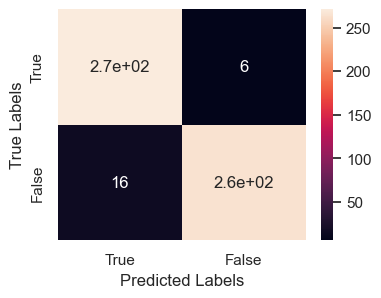

In [218]:
#plot the confusion matrix
plt.figure(figsize = (4,3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, xticklabels=['True', 'False'], yticklabels=['True', 'False'])

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [219]:
# print classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.94      0.98      0.96       277
        True       0.98      0.94      0.96       280

    accuracy                           0.96       557
   macro avg       0.96      0.96      0.96       557
weighted avg       0.96      0.96      0.96       557



### Feature Importance

In [220]:
importance = pd.DataFrame(np.array([tree.feature_names_in_, 
                                   tree.feature_importances_]
                                  ).T,
                         columns =['Features', 'Importance'])

In [221]:
importance.sort_values('Importance', ascending = False)

,Features,Importance
57,casualty_severity,0.897133
7,number_of_casualties,0.091258
13,speed_limit,0.011608
0,accident_year_x,0.0
47,engine_capacity_cc,0.0
...,...,...
28,vehicle_index,0.0
29,accident_year_y,0.0
30,vehicle_type,0.0
31,towing_and_articulation,0.0


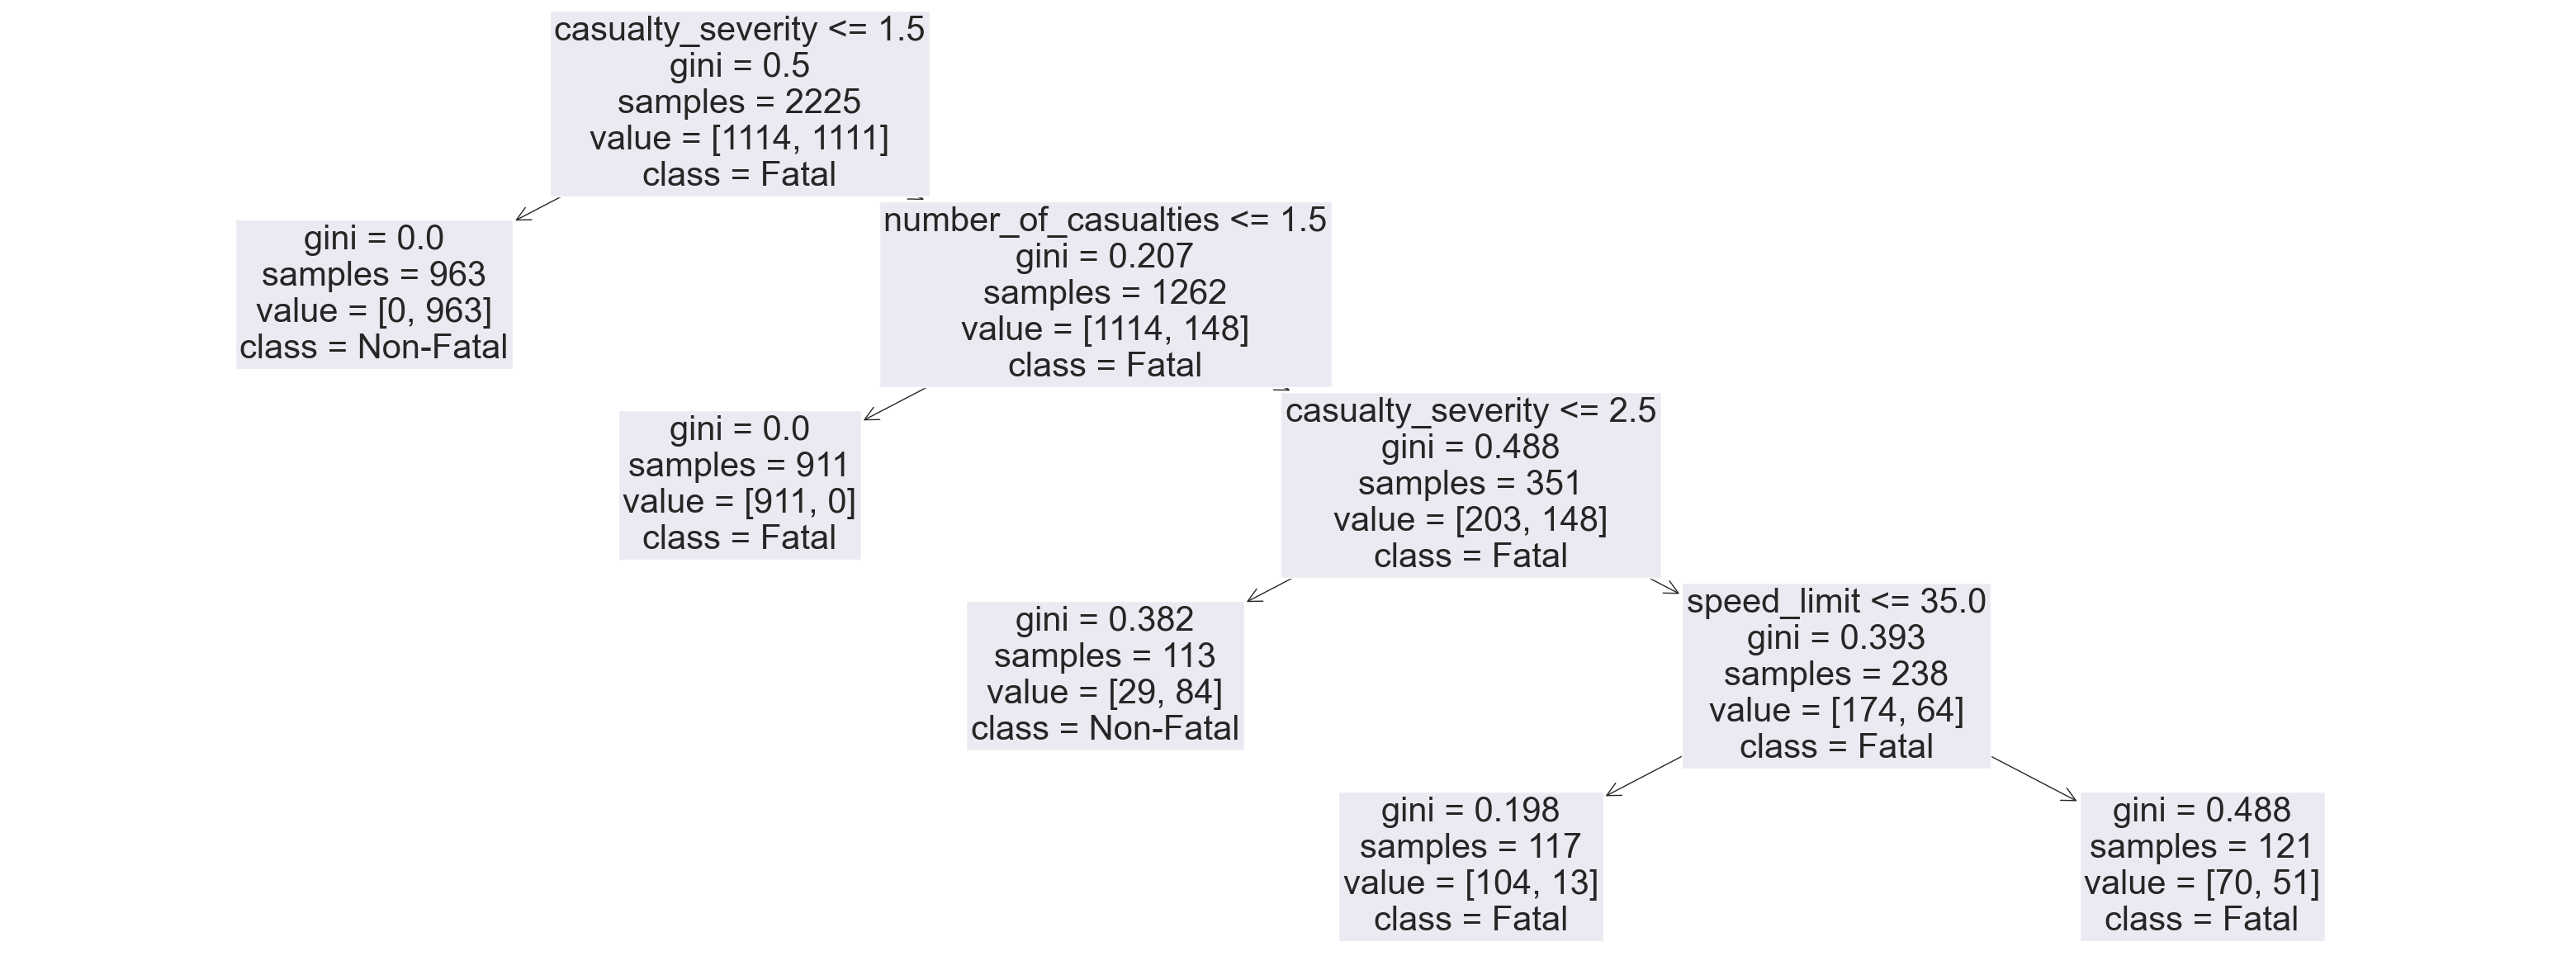

In [222]:
plt.figure(figsize=(40,15))
plot_tree(tree, feature_names = tree.feature_names_in_,
         class_names = ['Fatal', 'Non-Fatal'], fontsize =30)
plt.show()

#### Stacking Classifiers

In [223]:
#I will deine a stacking classifier in a function below
def stacker():
    level0 = []  # create a list of classifiers to use as level 0
    level0.append(('knn', KNeighborsClassifier()))
    level0.append(('bayes', GaussianNB()))
    level0.append(('dtree', DecisionTreeClassifier(min_samples_leaf = 100)))
    
    
    level1 = LogisticRegression() #appling logistic reg as level1
    
    model = StackingClassifier(estimators = level0, final_estimator=level1, cv =10)
    return model



In [231]:
#I will define a function to easily call the model results later
def build_model():
    models = dict()           #creates a dictiary to include all the classifiers
    models['dtree'] = DecisionTreeClassifier()   
    models['knn'] = KNeighborsClassifier()
    models['bayes'] = GaussianNB()
    models['stacker'] = stacker()
    
    return models

In [232]:
# I will define a function to exceute each model 
def exe_model(model, x, y):
    '''
    evaluate a model
    '''
    #do cross validation
    cv =  RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
    #get the scores
    scores = cross_val_score(model, x, y, scoring='accuracy', cv=cv, error_score='raise')
    
    return scores
     
    

In [233]:
#execute the model 
models = build_model()

In [234]:
#excecutes each of the model and get the results
names = []
results = []
for m, model in models.items():
    scores = exe_model(model, x_train, y_train)
    results.append(scores)
    names.append(m)

    print(f"{m}: {mean(scores) :3.2f} {std(scores): 4.3f}")

dtree: 0.94  0.015
knn: 0.57  0.038
bayes: 0.55  0.019
stacker: 0.96  0.012


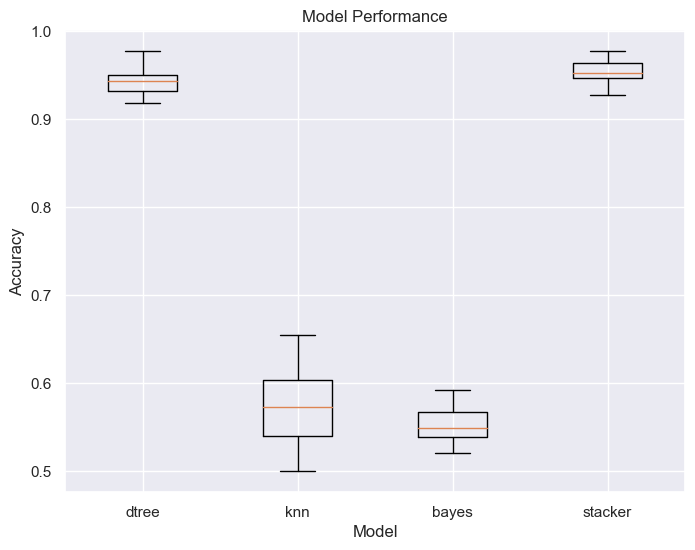

In [235]:
plt.figure(figsize=(8, 6))
plt.boxplot(results, labels=names)
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Model Performance')
plt.show()

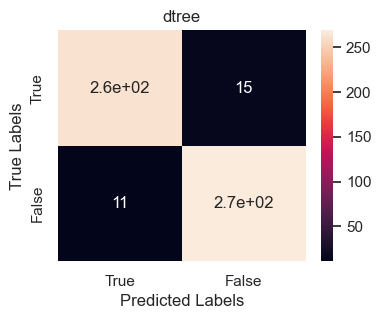

              precision    recall  f1-score   support

       False       0.96      0.95      0.95       277
        True       0.95      0.96      0.95       280

    accuracy                           0.95       557
   macro avg       0.95      0.95      0.95       557
weighted avg       0.95      0.95      0.95       557



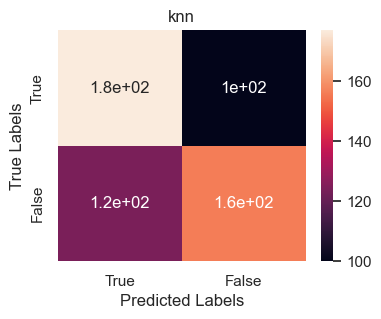

              precision    recall  f1-score   support

       False       0.59      0.64      0.61       277
        True       0.61      0.56      0.58       280

    accuracy                           0.60       557
   macro avg       0.60      0.60      0.60       557
weighted avg       0.60      0.60      0.60       557



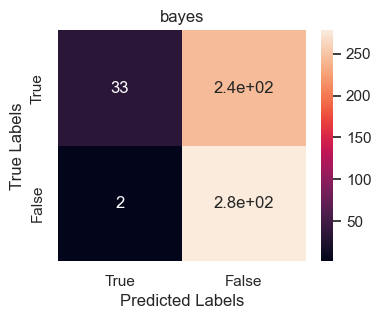

              precision    recall  f1-score   support

       False       0.94      0.12      0.21       277
        True       0.53      0.99      0.69       280

    accuracy                           0.56       557
   macro avg       0.74      0.56      0.45       557
weighted avg       0.74      0.56      0.45       557



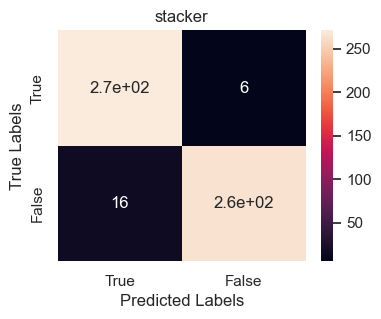

              precision    recall  f1-score   support

       False       0.94      0.98      0.96       277
        True       0.98      0.94      0.96       280

    accuracy                           0.96       557
   macro avg       0.96      0.96      0.96       557
weighted avg       0.96      0.96      0.96       557



In [236]:
#excecutes each of the model and get the results
names = []
results = []
for m, model in models.items():
    model.fit(x_train, y_train)
    #predict withthe test data
    y_pred = model.predict(x_test)
    
    plt.figure(figsize = (4,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, xticklabels=['True', 'False'], yticklabels=['True', 'False'])

    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title(m)
    plt.show()
    
    print(classification_report(y_test, y_pred))
    

## Notes

Ideas for all codes used are derived from:

1. Codes used in the class notebooks
2. Codes used in other courses in this M.Sc  
3. https://pandas.pydata.org/docs/reference/index.html
4. https://seaborn.pydata.org/
5. https://scikit-learn.org/stable/